# ProofBangla — Master Experiments
**Cross-Lingual Transfer and Domain-Shift Robustness of Hallucination Detection for Bengali RAG**

Single self-contained notebook: Stage 0 (setup) → Stage 9 (manifest + paper summary).
Every prediction is cached in `./predictions/<exp_id>_<model>_seed<seed>.jsonl`; re-running resumes instantly.

**Data access:** put raw files in `./data/raw/<key>.{parquet,jsonl,json,csv}` (or `./data/raw/<key>/<split>.*`)
for `ragtruth, banghallu, olikbochon, banglagovrag, bdlegalqa`, or set env `PB_<KEY>_HF=<hf repo id>`.
Hugging Face ids in `HF_CANDIDATES` (Stage 1) are best guesses; confirm them against your proposal.

---
### Running on an 8 GB GPU (RTX 4060, Windows)
1. **Once, in the NVIDIA Control Panel:** Manage 3D settings -> *CUDA - Sysmem Fallback Policy* -> **Prefer No Sysmem Fallback**.
   Without it Windows silently spills GPU memory into system RAM, which slows everything down and can freeze the PC.
2. Close other GPU programs (browser hardware acceleration, games) and **restart the kernel** after any CUDA out-of-memory error.
3. This notebook caps PyTorch at ~90% of VRAM, estimates the memory a training run needs *before* touching the GPU, switches to an 8-bit
   optimizer automatically if needed, halves batch sizes on OOM, and writes per-epoch resume files. Interrupt freely and re-run a cell to continue.


## Stage 0 — Setup, configuration, utilities

In [1]:
# Stage 0.1 — environment is managed outside the notebook
# By default, do NOT pip-install packages from inside a running notebook.
# Use the provided Conda environment and requirements file. Set PB_ALLOW_NOTEBOOK_INSTALL=1
# only if you deliberately want this notebook to install/update packages.
import os, sys, subprocess, importlib

INSTALL = os.environ.get("PB_ALLOW_NOTEBOOK_INSTALL", "0") == "1"

def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", *pkgs])

if INSTALL:
    try:
        import torch  # noqa
    except ImportError:
        _pip("torch")
    _pip("transformers>=4.48,<5", "datasets", "accelerate", "scikit-learn", "scipy", "statsmodels",
         "rank_bm25", "sentence-transformers", "faiss-cpu", "bitsandbytes",
         "seaborn", "matplotlib", "pandas", "numpy", "tqdm", "sentencepiece", "protobuf")
    _pip("git+https://github.com/csebuetnlp/normalizer")
else:
    print("Notebook-managed installation skipped; use the prepared Conda environment.")


Notebook-managed installation skipped; use the prepared Conda environment.


In [2]:
# Stage 0.2 — imports, flags, directories, determinism, hardware
import os as _os; _os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "max_split_size_mb:128,garbage_collection_threshold:0.8")   # less fragmentation (set before CUDA starts)
import gc, json, time, math, random, hashlib, re, warnings, platform, unicodedata, itertools, collections, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

SEEDS_FULL = [42, 1337, 2026]
FAST_SINGLE_SEED = False                 # True => debug with seed 42 only
SEEDS = [42] if FAST_SINGLE_SEED else SEEDS_FULL
ABLATION_SEEDS = SEEDS[:1]               # ablations that need re-training use the first seed only
FRACTIONS = [0.0, 0.10, 0.25, 1.0]
N_BOOT = 1000
LLM_EVAL_N = 600                         # stratified subset for M6 (None => full set)
SAVE_CKPT = True                         # keep fine-tuned checkpoints (fp16) for frozen transfer evals
ROOT = Path(".")
D = {k: ROOT / k for k in ["data/raw", "data/unified", "predictions", "tables", "figures", "results", "checkpoints", "cache"]}
for p in D.values():
    p.mkdir(parents=True, exist_ok=True)
RAW, UNI, PRED, TAB, FIG, RES, CKPT, CACHE = (D[k] for k in ["data/raw", "data/unified", "predictions", "tables", "figures", "results", "checkpoints", "cache"])

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE == "cuda" else 0.0
BF16_OK = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.bfloat16 if BF16_OK else (torch.float16 if DEVICE == "cuda" else torch.float32)
# dynamic batch sizing: (train micro-batch, infer batch) from VRAM; effective train batch is fixed at 16 by accumulation
if VRAM_GB >= 14:   TRAIN_BS, INFER_BS = 8, 32
elif VRAM_GB >= 7:  TRAIN_BS, INFER_BS = 2, 8
else:               TRAIN_BS, INFER_BS = 1, 2
EFFECTIVE_BS = 16
GRAD_CKPT = VRAM_GB < 12                 # (trainer now enables checkpointing only for large / long-context models)
LOW_VRAM = VRAM_GB < 12
GPU_CAP = 0.90 if LOW_VRAM else 1.0       # fraction of VRAM PyTorch may use
if DEVICE == "cuda" and LOW_VRAM:
    torch.cuda.set_per_process_memory_fraction(GPU_CAP, 0)   # an over-allocation raises a catchable OOM instead of spilling into system RAM
    print(f"[profile] {VRAM_GB:.1f} GB GPU: memory cap {GPU_CAP:.0%}, token-budget batching, per-epoch resume files")
print(f"device={DEVICE} gpu={torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'cpu'} vram={VRAM_GB:.1f}GB amp={AMP_DTYPE} "
      f"train_bs={TRAIN_BS} infer_bs={INFER_BS} grad_ckpt={GRAD_CKPT} seeds={SEEDS}")

def free_gpu(*objs):
    for o in objs:
        del o
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.synchronize()

[profile] 8.0 GB GPU: memory cap 90%, token-budget batching, per-epoch resume files
device=cuda gpu=NVIDIA GeForce RTX 4060 vram=8.0GB amp=torch.bfloat16 train_bs=2 infer_bs=8 grad_ckpt=True seeds=[42, 1337, 2026]


In [3]:
# Stage 0.3 — model registry & global result stores
MODELS = {
    "ModernBERT":  "answerdotai/ModernBERT-base",
    "EuroBERT":    "EuroBERT/EuroBERT-210m",
    "XLM-R-base":  "xlm-roberta-base",
    "BanglaBERT-large": "csebuetnlp/banglabert_large",
}
# Released checkpoints verified against the official Hugging Face model collection.
# Note: the EuroBERT LettuceDetect releases are language-specific fine-tunes, not one
# universal "multilingual" classifier. M2 is explicitly the published Chinese RAGTruth fine-tune.
M1_CANDIDATES = ["KRLabsOrg/lettucedect-base-modernbert-en-v1"]
M2_CANDIDATES = ["KRLabsOrg/lettucedect-210m-eurobert-cn-v1"]
REQUIRE_RELEASED_M1 = True
REQUIRE_RELEASED_M2 = True
M2_SOURCE_DATASET = "KRLabsOrg/ragtruth-cn-translated"
RUN_M2STAR_SUPPLEMENTARY = False  # Enable only after released M1/M2 have been verified.
M2STAR_BACKBONE = "EuroBERT/EuroBERT-210m"
M2STAR_EPOCHS = 3
MODEL_REVISIONS = {
    "KRLabsOrg/lettucedect-base-modernbert-en-v1": "bbd77832f52f9bd87546a3924c032467921f5c34",
    "KRLabsOrg/lettucedect-210m-eurobert-cn-v1": "2ab71cb08fa068e932b5fbdbeb5e394ae8978970",
}
EUROBERT_BACKBONE_REVISION = "1babc6fa0e22d779c807ecbf93ca1aa646143a75"
EUROBERT_CODE_REVISION = "1babc6fa0e22d779c807ecbf93ca1aa646143a75"
M5_BACKBONE = "xlm-roberta-base"
M6_LLM = "Qwen/Qwen2.5-3B-Instruct"
E5_MODEL = "intfloat/multilingual-e5-base"

THRESHOLDS = {}      # model key -> tau* tuned on dev (frozen for test)
RESOURCES_PATH = RES / "resources.json"
RESOURCES = json.loads(RESOURCES_PATH.read_text()) if RESOURCES_PATH.exists() else {}
def log_resource(key, peak_vram_mb):
    RESOURCES[key] = {"peak_vram_mb": float(peak_vram_mb)}
    RESOURCES_PATH.write_text(json.dumps(RESOURCES, indent=1))
TAU_PATH = RES / "thresholds.json"
if TAU_PATH.exists():
    THRESHOLDS.update(json.loads(TAU_PATH.read_text()))
def set_tau(key, tau):
    THRESHOLDS[key] = float(tau); TAU_PATH.write_text(json.dumps(THRESHOLDS, indent=1))

In [4]:
# Stage 0.4 — evaluation metrics
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, average_precision_score

def macro_f1(y, pred):
    return float(f1_score(y, pred, average="macro", zero_division=0))

def ece_score(y, p, n_bins=10):
    """Top-label ECE on P(hallucinated)=p (confidence = max(p,1-p), accuracy of argmax label)."""
    y = np.asarray(y); p = np.asarray(p, float)
    pred = (p >= 0.5).astype(int); conf = np.maximum(p, 1 - p); acc = (pred == y).astype(float)
    bins = np.linspace(0.5, 1.0, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

def safe_auc(y, p, kind="roc"):
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return float("nan")
    return float(roc_auc_score(y, p) if kind == "roc" else average_precision_score(y, p))

def tune_tau(y, p):
    """Threshold maximising Macro-F1 on dev."""
    y = np.asarray(y); p = np.asarray(p, float)
    cands = np.unique(np.concatenate([np.quantile(p, np.linspace(0.02, 0.98, 97)), [0.5]]))
    best, best_f = 0.5, -1
    for t in cands:
        f = macro_f1(y, (p >= t).astype(int))
        if f > best_f + 1e-12:
            best, best_f = float(t), f
    return best

def full_metrics(y, p, tau):
    y = np.asarray(y); p = np.asarray(p, float); pred = (p >= tau).astype(int)
    return dict(macro_f1=macro_f1(y, pred),
                precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred, zero_division=0)),
                auroc=safe_auc(y, p, "roc"), auprc=safe_auc(y, p, "pr"),
                ece=ece_score(y, p), accuracy=float((pred == y).mean()), n=int(len(y)))

def _macro_f1_batch(y, pred):
    """Vectorised macro-F1 for arrays shaped (B,N)."""
    f = 0.0
    for c in (0, 1):
        tp = ((pred == c) & (y == c)).sum(1); fp = ((pred == c) & (y != c)).sum(1); fn = ((pred != c) & (y == c)).sum(1)
        d = 2 * tp + fp + fn
        f = f + np.where(d > 0, 2 * tp / np.maximum(d, 1), 0.0)
    return f / 2

def boot_indices(n, B=N_BOOT, seed=0):
    return np.random.default_rng(seed).integers(0, n, size=(B, n))

def bootstrap_ci_single(y, pred, B=N_BOOT, seed=0):
    y = np.asarray(y); pred = np.asarray(pred); idx = boot_indices(len(y), B, seed)
    s = _macro_f1_batch(y[idx], pred[idx]); return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

def bootstrap_ci_multiseed(y, preds_by_seed, B=N_BOOT, seed=0):
    """CI of the seed-averaged Macro-F1, resampling examples jointly across seeds."""
    y = np.asarray(y); idx = boot_indices(len(y), B, seed)
    s = np.mean([_macro_f1_batch(y[idx], np.asarray(p)[idx]) for p in preds_by_seed], axis=0)
    return float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

In [5]:
# Stage 0.5 — CSV / LaTeX / figure export utilities
plt.style.use("seaborn-v0_8-whitegrid")
PALETTE = sns.color_palette("colorblind")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "figure.dpi": 110, "savefig.dpi": 300,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})

def _num(x):
    if isinstance(x, (int, float, np.integer, np.floating)) and not (isinstance(x, float) and math.isnan(x)):
        return float(x)
    if isinstance(x, str):
        m = re.match(r"^\s*(-?\d+(?:\.\d+)?)", x)
        if m:
            return float(m.group(1))
    return None

_TEX_MAP = [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#"), ("$", r"\$"),
            ("±", r"$\pm$"), ("Δ", r"$\Delta$"), ("χ²", r"$\chi^2$"), ("τ", r"$\tau$"), ("≥", r"$\geq$"), ("→", r"$\rightarrow$")]
def tex_escape(s):
    s = str(s)
    for a, b in _TEX_MAP:
        s = s.replace(a, b)
    return s

def _fmt_cell(x, digits=3):
    if isinstance(x, (float, np.floating)):
        return "--" if math.isnan(x) else f"{x:.{digits}f}"
    if isinstance(x, (int, np.integer)):
        return str(x)
    return "--" if x is None else str(x)

def save_table(df, name, caption, higher_better=(), lower_better=(), group_col=None, digits=3, label=None, note=None):
    """Write ./tables/<name>.csv and booktabs ./tables/<name>.tex (best bold, second-best underlined)."""
    df = df.copy().reset_index(drop=True)
    df.to_csv(TAB / f"{name}.csv", index=False)
    groups = [df.index] if group_col is None else [g.index for _, g in df.groupby(group_col, sort=False)]
    mark = {}
    for cols, hb in ((higher_better, True), (lower_better, False)):
        for col in cols:
            if col not in df.columns:
                continue
            for gi in groups:
                vals = [(i, _num(df.at[i, col])) for i in gi]
                vals = [(i, v) for i, v in vals if v is not None]
                uniq = sorted({round(v, 10) for _, v in vals}, reverse=hb)
                if len(vals) < 2 or not uniq:
                    continue
                for i, v in vals:
                    r = round(v, 10)
                    if r == uniq[0]: mark[(i, col)] = "b"
                    elif len(uniq) > 1 and r == uniq[1]: mark[(i, col)] = "u"
    cols = list(df.columns)
    lines = [r"\begin{table*}[t]" if len(cols) > 7 else r"\begin{table}[t]", r"\centering", r"\small",
             rf"\caption{{{tex_escape(caption)}}}", rf"\label{{{label or 'tab:' + name}}}",
             r"\resizebox{\linewidth}{!}{%", r"\begin{tabular}{" + "l" * 1 + "c" * (len(cols) - 1) + "}", r"\toprule",
             " & ".join(tex_escape(c) for c in cols) + r" \\", r"\midrule"]
    prev = None
    for i, row in df.iterrows():
        if group_col is not None and prev is not None and row[group_col] != prev:
            lines.append(r"\midrule")
        prev = row[group_col] if group_col is not None else None
        cells = []
        for c in cols:
            s = tex_escape(_fmt_cell(row[c], digits))
            m = mark.get((i, c))
            s = rf"\textbf{{{s}}}" if m == "b" else (rf"\underline{{{s}}}" if m == "u" else s)
            cells.append(s)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}}"]
    if note:
        lines.append(rf"\\[2pt]\footnotesize {tex_escape(note)}")
    lines.append(r"\end{table*}" if len(cols) > 7 else r"\end{table}")
    (TAB / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")
    print(f"[table] saved {name}.csv/.tex ({len(df)} rows)")
    return df

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)
    print(f"[figure] saved {name}.png/.pdf @300dpi")

def mean_sd(vals, digits=3):
    v = np.asarray([x for x in vals if x is not None and not np.isnan(x)], float)
    if len(v) == 0: return "--"
    return f"{v.mean():.{digits}f} ± {v.std(ddof=1) if len(v) > 1 else 0.0:.{digits}f}"

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

In [6]:
# Stage 0.6 — prediction cache (idempotent / resumable)
def pred_path(exp, model, seed):
    return PRED / f"{exp}_{model}_seed{seed}.jsonl"

def save_preds(path, recs):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    tmp.replace(path)

def load_preds(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

class Lazy:
    """Creates an expensive scorer only on first use and always frees GPU memory on exit."""
    def __init__(self, factory, key=None):
        self.factory, self.obj, self.key = factory, None, key
    def get(self):
        if self.obj is None:
            reset_gpu()
            if torch.cuda.is_available():
                torch.cuda.reset_peak_memory_stats()
            self.obj = self.factory()
        return self.obj
    def __enter__(self): return self
    def __exit__(self, *a):
        if self.obj is not None:
            if self.key and torch.cuda.is_available():
                log_resource(self.key, torch.cuda.max_memory_allocated() / 2**20)
            elif self.key:
                log_resource(self.key, 0.0)
            self.obj = None
        free_gpu()

def cached_predict(exp, model, seed, df, lazy, tau=0.5):
    """Return per-example records; load from disk if already computed."""
    p = pred_path(exp, model, seed)
    if p.exists():
        recs = load_preds(p)
        if [r["id"] for r in recs] == [str(i) for i in df["id"]]:
            for r in recs:
                r["pred_label"] = int(r["pred_prob"] >= tau)
            return recs
    recs = lazy.get().predict(df)
    for r in recs:
        r["pred_label"] = int(r["pred_prob"] >= tau)
    save_preds(p, recs)
    return recs

def recs_arrays(recs):
    return (np.array([r["gold_label"] for r in recs], int), np.array([r["pred_prob"] for r in recs], float))

def pool_scores(token_probs, rule="max"):
    tp = np.asarray(token_probs, float)
    if tp.size == 0: return 0.0
    if rule == "max": return float(tp.max())
    k = int(rule.replace("top", "").replace("_mean", ""))
    return float(np.sort(tp)[::-1][:k].mean())

print("Stage 0 complete.")

Stage 0 complete.


In [7]:
# Stage 0.7 — GPU safety helpers (8 GB friendly)
OPTIMIZER_DEFAULT = "adamw_fused"       # "adamw_fused" (no temporary buffers) | "adamw8bit" (~2 GB less on BanglaBERT-large) | "adamw"

def reset_gpu():
    """Release everything that can be released: dead tensors, the notebook's stored exception traceback (it keeps OOM'd tensors alive!), CUDA cache."""
    for a in ("last_type", "last_value", "last_traceback"):
        if hasattr(sys, a): setattr(sys, a, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.synchronize()

def gpu_avail_gb():
    """GB that can still be allocated: the smaller of the driver's free memory and the PyTorch cap minus what PyTorch already reserved."""
    if DEVICE != "cuda": return 1e9
    total = torch.cuda.get_device_properties(0).total_memory
    free, _ = torch.cuda.mem_get_info()
    return min(total * GPU_CAP - torch.cuda.memory_reserved(), free) / 2**30

def gpu_status():
    if DEVICE != "cuda": return ""
    return f"[gpu alloc {torch.cuda.memory_allocated() / 2**30:.1f} / peak {torch.cuda.max_memory_allocated() / 2**30:.1f} GB]"

def build_optimizer(groups, lr, name):
    kw = dict(lr=lr, betas=(0.9, 0.999), eps=1e-8)
    if name == "adamw8bit":
        try:
            import bitsandbytes as bnb
            return bnb.optim.AdamW8bit(groups, **kw), "adamw8bit"
        except Exception as e:
            print("[train] bitsandbytes 8-bit AdamW unavailable -> fused AdamW:", type(e).__name__); name = "adamw_fused"
    if name == "adamw_fused" and DEVICE == "cuda":
        return torch.optim.AdamW(groups, fused=True, **kw), "adamw_fused"          # single fused kernel: no foreach temporaries (the 5.4 OOM)
    return torch.optim.AdamW(groups, foreach=False, **kw), "adamw"

print("GPU helpers ready.", gpu_status())

GPU helpers ready. [gpu alloc 0.0 / peak 0.0 GB]


## Stage 1 — Experiment A: unified schema, leakage checks, context-only truncation, tokenizer audit

In [8]:
# Stage 1.1 — raw loaders (local files > env HF id > candidate HF ids)
from datasets import load_dataset
SCHEMA = ["id", "dataset", "split", "question", "context", "answer", "label_answer", "label_spans", "evidence_spans", "source_url", "metadata"]
HF_CANDIDATES = {   # best-guess ids: VERIFY against your proposal or override via ./data/raw/<key>.* / env PB_<KEY>_HF
    "ragtruth":     ["wandb/RAGTruth-processed", "KRLabsOrg/ragtruth-en"],
    "banghallu":    ["csebuetnlp/BanglaHallu", "BanglaNLP/BangHallu", "Bhibranti/BangHallu"],
    "olikbochon":   [],   # Olikbochon is the Kaggle competition "bengali-hallucination" (see KAGGLE_COMPETITIONS)
    "banglagovrag": ["BanglaNLP/BanglaGovRAG", "BanglaGovRAG/BanglaGovRAG"],
    "bdlegalqa":    ["momahadi/bangladesh-legal-qa-dataset"],
}
LICENSES = {"ragtruth": "MIT", "banghallu": "see source card", "olikbochon": "see source card",
            "banglagovrag": "see source card", "bdlegalqa": "see source card"}
LABEL_MEANS_FAITHFUL = {"banghallu": True,   # BangHallu repo convention: 1 = faithful/correct, 0 = hallucinated (inverted here so 1 = hallucinated everywhere)
                          "olikbochon": True, "banglagovrag": False, "bdlegalqa": False, "ragtruth": False}   # CHECK Olikbochon's label polarity
SPLIT_ALIASES = {"validation": "dev", "internal_test": "test", "val": "dev", "valid": "dev", "dev": "dev", "train": "train", "training": "train", "test": "test", "testing": "test", "all": "all"}

GITHUB_REPOS = {   # official GitHub sources, auto-cloned into ./data/raw/<key>/ when no local data is present
    "banghallu":    "https://github.com/mayer-doa-coder/Bhibranti.git",
    "banglagovrag": "https://github.com/shoumya-chy/banglagovrag.git",
    "bdlegalqa":    "https://github.com/m-mahadi/bangladesh-legal-qa.git",
}
DATA_EXTS = (".parquet", ".jsonl", ".json", ".csv")
SKIP_NAMES = {"package.json", "package-lock.json", "tsconfig.json", "composer.json", ".eslintrc.json", "config.json"}

def _read_any(p: Path):
    s = p.suffix.lower()
    if s == ".parquet": return pd.read_parquet(p)
    if s == ".jsonl":   return pd.read_json(p, lines=True)
    if s == ".json":
        try: return pd.read_json(p)
        except ValueError: return pd.read_json(p, lines=True)
    if s == ".csv":
        try: return pd.read_csv(p)
        except UnicodeDecodeError: return pd.read_csv(p, encoding="utf-8-sig")
    raise ValueError(p)

CANONICAL_FILES = {   # the repos' own dataset files; used first so annotation sheets, raw pools and 1 GB of benchmark-run logs are NOT ingested
    "banghallu": ["data/splits/train.jsonl", "data/splits/dev.jsonl", "data/splits/test.jsonl"],
    "banglagovrag": ["benchmark/benchmark_v1.1.csv"],
    "bdlegalqa": ["03-qa-dataset/train-val-test-split/train.jsonl", "03-qa-dataset/train-val-test-split/validation.jsonl", "03-qa-dataset/train-val-test-split/internal_test.jsonl"],
}
def _data_files(d: Path, key=None):
    canon = [d / p for p in CANONICAL_FILES.get(key, []) if (d / p).is_file()]
    if canon: return canon
    return [f for f in sorted(d.rglob("*")) if f.is_file() and f.suffix.lower() in DATA_EXTS and ".git" not in f.parts and f.name.lower() not in SKIP_NAMES]

KAGGLE_COMPETITIONS = {"olikbochon": "bengali-hallucination"}   # https://www.kaggle.com/competitions/bengali-hallucination/

def fetch_kaggle(key):
    """Download a Kaggle competition into ./data/raw/<key>/ (needs ~/.kaggle/kaggle.json or KAGGLE_USERNAME/KAGGLE_KEY, and accepted competition rules).
    Manual fallback: download the zip from the competition Data tab and unzip it into ./data/raw/<key>/."""
    comp = KAGGLE_COMPETITIONS.get(key); d = RAW / key
    if comp is None: return False
    if d.is_dir() and _data_files(d, key): return True
    try:
        try: from kaggle.api.kaggle_api_extended import KaggleApi
        except Exception:
            _pip("kaggle"); from kaggle.api.kaggle_api_extended import KaggleApi
        api = KaggleApi(); api.authenticate(); d.mkdir(parents=True, exist_ok=True)
        print(f"[fetch] kaggle competitions download -c {comp} -> {d}")
        api.competition_download_files(comp, path=str(d), quiet=False)
        for z in d.glob("*.zip"):
            shutil.unpack_archive(str(z), str(d)); z.unlink()
    except Exception as e:
        print(f"[WARN] Kaggle download failed for {key}: {type(e).__name__}: {str(e)[:200]}\n"
              f"       -> accept the rules at https://www.kaggle.com/competitions/{comp}/rules, set Kaggle credentials, or unzip the data manually into {d}/")
        return False
    return bool(_data_files(d, key))

def fetch_github(key):
    """git clone the official repo into ./data/raw/<key>/ if no data files exist there yet. Returns True if data files are available."""
    d = RAW / key
    if d.is_dir() and _data_files(d, key): return True
    url = GITHUB_REPOS.get(key)
    if url is None: return False
    try:
        if d.exists(): shutil.rmtree(d, ignore_errors=True)
        print(f"[fetch] git clone {url} -> {d}")
        subprocess.check_call(["git", "clone", "--depth", "1", url, str(d)])
    except Exception as e:
        print(f"[WARN] git clone failed for {key}: {type(e).__name__}: {str(e)[:200]}")
        return False
    return bool(_data_files(d, key))

def _read_dir(d: Path, key=None):
    """Read and concatenate every JSONL/CSV/Parquet/JSON file under d (recursively). Split = alias of file stem or parent dir name, else 'all'."""
    frames = collections.defaultdict(list)
    for f in _data_files(d, key):
        sp = SPLIT_ALIASES.get(f.stem.lower()) or next((SPLIT_ALIASES[p.lower()] for p in reversed(f.relative_to(d).parts[:-1]) if p.lower() in SPLIT_ALIASES), None) or \
             next((v for k, v in SPLIT_ALIASES.items() if k != "all" and re.search(rf"(^|[_\-.]){k}($|[_\-.])", f.stem.lower())), "all")
        try:
            df = _read_any(f)
        except Exception as e:
            print(f"[skip] {f}: {type(e).__name__}"); continue
        if len(df) and df.shape[1] >= 2:
            frames[sp].append(df.assign(_source_file=str(f.relative_to(d))))
    return {sp: pd.concat(v, ignore_index=True) for sp, v in frames.items()}

def load_raw(key):
    # Olikbochon has a labelled sample file plus an UNLABELLED test file and a
    # sample-submission template. Only the labelled sample file is valid gold data.
    if key == "olikbochon":
        d = RAW / key
        sample_files = sorted(d.rglob("dataset samples.json")) if d.exists() else []
        if not sample_files and not (d.exists() and _data_files(d, key)):
            fetch_kaggle(key)
            sample_files = sorted(d.rglob("dataset samples.json")) if d.exists() else []
        if sample_files:
            sample_path = sample_files[0]
            print(f"[load] olikbochon labelled sample only: {sample_path}")
            return {"all": _read_any(sample_path)}
        raise RuntimeError(
            f"Could not find the labelled 'dataset samples.json' under {d}. "
            "Do not use 'test set.csv' or 'sample submission.csv' as labelled evaluation data."
        )
    out = {}
    d = RAW / key
    if d.is_dir() and _data_files(d, key):
        out = _read_dir(d, key)
    if not out:
        for ext in ("parquet", "jsonl", "json", "csv"):
            f = RAW / f"{key}.{ext}"
            if f.exists():
                out["all"] = _read_any(f); break
    if not out and key in GITHUB_REPOS and fetch_github(key):          # auto-fetch GitHub-hosted datasets
        out = _read_dir(d, key)
    if not out and key in KAGGLE_COMPETITIONS and fetch_kaggle(key):
        out = _read_dir(d, key)
    if out:
        print(f"[load] {key}: " + ", ".join(f"{k}={len(v)}" for k, v in out.items()))
        return out
    cands = [os.environ[f"PB_{key.upper()}_HF"]] if f"PB_{key.upper()}_HF" in os.environ else HF_CANDIDATES[key]
    errs = []
    for c in cands:
        try:
            dd = load_dataset(c)
            return {SPLIT_ALIASES.get(k, k): v.to_pandas() for k, v in dd.items()}
        except Exception as e:  # noqa
            errs.append(f"{c}: {type(e).__name__}: {str(e)[:120]}")
    raise RuntimeError(f"Could not load '{key}'. Put data under {RAW}/{key}/ (or {RAW}/{key}.<ext>), allow git clone, or set PB_{key.upper()}_HF.\n" + "\n".join(errs))

In [9]:
# Stage 1.2 — text helpers, label normalisation, column pickers
BN_DIGITS = str.maketrans("০১২৩৪৫৬৭৮৯", "0123456789")
BN_RANGE = re.compile(r"[\u0980-\u09FF]")
LAT_RANGE = re.compile(r"[A-Za-z]")
HALLU_WORDS = ("hallucinat", "unfaith", "incorrect", "unsupported", "false", "wrong", "contradict", "অসত্য", "ভুল")
FAITH_WORDS = ("faithful", "support", "correct", "true", "grounded", "right", "সত্য", "সঠিক")

def norm_label(v, faithful_means_1=False):
    if v is None or (isinstance(v, float) and math.isnan(v)): return None
    if isinstance(v, (bool, np.bool_)): r = int(v)
    elif isinstance(v, (int, np.integer, float, np.floating)): r = int(v)
    else:
        s = str(v).strip().lower()
        if s in ("1", "yes", "y"): r = 1
        elif s in ("0", "no", "n"): r = 0
        elif any(w in s for w in HALLU_WORDS) and not s.startswith(("not ", "non")): return 1
        elif any(w in s for w in FAITH_WORDS): return 0
        else: return None
        return (1 - r) if faithful_means_1 else r
    return (1 - r) if faithful_means_1 else r

def pick(df, cands):
    low = {c.lower(): c for c in df.columns}
    for c in cands:
        if c.lower() in low: return low[c.lower()]
    return None

def _to_list(v):
    if v is None or (isinstance(v, float) and math.isnan(v)): return []
    if isinstance(v, str):
        try: v = json.loads(v)
        except Exception: return []
    if isinstance(v, np.ndarray): v = v.tolist()
    return v if isinstance(v, list) else []

def _spans(v):
    out = []
    for s in _to_list(v):
        if isinstance(s, dict):
            a, b = s.get("start", s.get("start_char")), s.get("end", s.get("end_char"))
            if a is not None and b is not None: out.append([int(a), int(b)])
        elif isinstance(s, (list, tuple)) and len(s) >= 2: out.append([int(s[0]), int(s[1])])
    return out

def stable_id(*parts):
    return hashlib.md5("||".join(map(str, parts)).encode("utf-8")).hexdigest()[:16]

def qhash(q): return int(hashlib.md5(str(q).encode("utf-8")).hexdigest()[:8], 16)

In [10]:
# Stage 1.3 — dataset adapters -> unified nullable JSONL schema
Q_C = ["question", "query", "prompt_question", "instruction", "প্রশ্ন", "prompt_bn"]
C_C = ["context", "passage_text", "passage", "passages", "evidence", "document", "reference", "source", "text", "প্রসঙ্গ"]
A_C = ["answer", "candidate_answer", "answer_span", "response", "generated_answer", "model_answer", "claim", "output", "উত্তর", "response_bn"]
L_C = ["label", "hallucination", "is_hallucinated", "hallucinated", "hallucination_label", "label_answer", "is_hallucination", "factuality"]
POS_PAIR = ["correct_answer", "answer_correct", "positive_answer", "faithful_answer", "gold_answer", "right_answer", "answer_faithful"]
NEG_PAIR = ["hallucinated_answer", "answer_hallucinated", "negative_answer", "incorrect_answer", "wrong_answer", "unfaithful_answer"]

def _ctx_to_str(v):
    if isinstance(v, (list, tuple, np.ndarray)): return "\n".join(str(x) for x in v)
    if isinstance(v, str) and v.strip().upper() == "[NULL]": return ""
    return "" if v is None or (isinstance(v, float) and math.isnan(v)) else str(v)

def adapt_ragtruth(df, split):
    qc, cc, ac = pick(df, Q_C), pick(df, ["context", "prompt", "passages", "source_info"]), pick(df, ["answer", "response", "output"])
    lc = pick(df, ["labels", "hallucination_labels", "hallucination_spans", "label_spans"])
    qual, task = pick(df, ["quality"]), pick(df, ["task_type", "task"])
    rows = []
    for i, r in df.iterrows():
        if qual and str(r[qual]).lower() not in ("good", "nan", "none", ""): continue
        sp = _spans(r[lc]) if lc else []
        lab = norm_label(r[pick(df, L_C)]) if pick(df, L_C) and not lc else int(len(sp) > 0)
        rows.append(dict(id=stable_id("ragtruth", split, i), dataset="ragtruth", split=split, question=str(r[qc]) if qc else "",
                         context=_ctx_to_str(r[cc]), answer=str(r[ac]), label_answer=lab, label_spans=sp, evidence_spans=[],
                         source_url="", metadata={"task": str(r[task]) if task else ""}))
    return pd.DataFrame(rows, columns=SCHEMA)

def adapt_generic(df, key, split):
    qc, cc, ac, lc = pick(df, Q_C), pick(df, C_C), pick(df, A_C), pick(df, L_C)
    pc, nc = pick(df, POS_PAIR), pick(df, NEG_PAIR)
    evc, uc, spc = pick(df, ["evidence_spans", "evidence"]), pick(df, ["source_url", "url", "link"]), pick(df, ["label_spans", "spans", "hallucination_spans"])
    fm1 = LABEL_MEANS_FAITHFUL.get(key, False)
    exc = pick(df, ["excluded"])                                   # BangHallu: rows flagged as excluded by the authors
    if exc: df = df[~df[exc].astype(str).str.lower().isin(["true", "1"])]
    tt = pick(df, ["training_task"])                               # BD Legal QA: MCQ rows have letter answers -> keep free-text QA only
    if tt: df = df[df[tt].astype(str) == "direct_qa"]
    rows = []
    for i, r in df.iterrows():
        base = dict(dataset=key, split=split, question=str(r[qc]) if qc else "", context=_ctx_to_str(r[cc]) if cc else "",
                    evidence_spans=_to_list(r[evc]) if evc and evc != cc else [], source_url=str(r[uc]) if uc else "")
        meta = {k: (v if isinstance(v, (str, int, float, bool)) else str(v)) for k, v in r.items() if k not in (qc, cc, ac, lc, pc, nc) and not isinstance(v, (list, dict, np.ndarray))}
        if pc and nc:                       # paired positive/negative answers on one row
            rows.append(dict(base, id=stable_id(key, split, i, "pos"), answer=str(r[pc]), label_answer=0, label_spans=[], metadata=dict(meta, pair="pos")))
            rows.append(dict(base, id=stable_id(key, split, i, "neg"), answer=str(r[nc]), label_answer=1, label_spans=[], metadata=dict(meta, pair="neg")))
        elif ac:
            lab = norm_label(r[lc], fm1) if lc else None
            rows.append(dict(base, id=stable_id(key, split, i), answer=str(r[ac]), label_answer=lab,
                             label_spans=_spans(r[spc]) if spc else [], metadata=meta))
    return pd.DataFrame(rows, columns=SCHEMA)

def grouped_split(df, fracs=(0.8, 0.1, 0.1), seed=42):
    """Question-grouped split so paired answers never straddle splits."""
    qs = sorted(df["question"].unique(), key=lambda q: qhash(str(q) + str(seed)))
    n = len(qs); a, b = int(fracs[0] * n), int((fracs[0] + fracs[1]) * n)
    m = {q: ("train" if i < a else "dev" if i < b else "test") for i, q in enumerate(qs)}
    out = df.copy(); out["split"] = out["question"].map(m); return out

def build_unified(key):
    raw = load_raw(key); frames = []
    for sp, d in raw.items():
        frames.append(adapt_ragtruth(d, sp) if key == "ragtruth" else adapt_generic(d, key, sp))
    df = pd.concat(frames, ignore_index=True)
    if "all" in set(df["split"]):
        if key == "ragtruth": raise RuntimeError("RAGTruth needs explicit train/test splits.")
        df = grouped_split(df.assign(split="all"))
    elif key in ("banghallu",):
        if "dev" not in set(df["split"]) and "train" in set(df["split"]):
            tr = df[df.split == "train"]; g = grouped_split(tr, (0.9, 0.1, 0.0)); df.loc[tr.index, "split"] = g["split"].values
        if "test" not in set(df["split"]):
            raise RuntimeError("banghallu has no test split; provide one in ./data/raw/banghallu/")
    return df

In [11]:
# Stage 1.4 — synthetic perturbations (used only to *construct* negatives when native labels are missing; always flagged)
EN_AUX = re.compile(r"\b(is|are|was|were|can|shall|may|must|will|has|have|does|do)\b", re.I)
SENT_END = re.compile(r"[।.!?]")

def _shift_digits(m):
    s = m.group(0); bn = s[0] in "০১২৩৪৫৬৭৮৯"
    v = int(s.translate(BN_DIGITS)); nv = v + random.choice([1, 2, 3, 5, 10]) if v < 1000 else v + 7
    out = str(nv); return out.translate(str.maketrans("0123456789", "০১২৩৪৫৬৭৮৯")) if bn else out

def perturb_answer(ans, pool_answers, rng):
    """Returns (perturbed_text, type) or (None, None). Types: number, negation, entity_swap, unsupported_addition."""
    options = []
    if re.search(r"[0-9০-৯]+", ans): options.append("number")
    options += ["negation", "entity_swap", "unsupported_addition"]
    rng.shuffle(options)
    for t in options:
        if t == "number":
            random.seed(rng.randint(0, 10**9))
            new = re.sub(r"[0-9০-৯]+", _shift_digits, ans, count=1)
            if new != ans: return new, t
        elif t == "negation":
            if BN_RANGE.search(ans):
                m = SENT_END.search(ans)
                if m and not re.search(r"(না|নয়|নেই)\s*[।.]?\s*$", ans[:m.start() + 1]):
                    return ans[:m.start()] + " না" + ans[m.start():], t
            else:
                m = EN_AUX.search(ans)
                if m: return ans[:m.end()] + " not" + ans[m.end():], t
        elif t == "entity_swap":
            words = [w for w in re.findall(r"\w+", ans) if len(w) >= 4 and not w.translate(BN_DIGITS).isdigit()]
            others = [w for a in rng.sample(pool_answers, min(8, len(pool_answers))) for w in re.findall(r"\w+", a) if len(w) >= 4 and w not in ans]
            if words and others:
                w = rng.choice(words); return ans.replace(w, rng.choice(others), 1), t
        elif t == "unsupported_addition":
            other = rng.choice(pool_answers); sents = [s.strip() for s in re.split(r"(?<=[।.!?])\s+", other) if len(s.strip()) > 15]
            if sents and other != ans: return ans.rstrip() + " " + rng.choice(sents), t
    return None, None

def synthesize_pairs(df, seed=42):
    """From rows with a (presumed faithful) answer build 1 faithful (label 0) + 1 perturbed (label 1) example. Flagged synthetic."""
    rng = random.Random(seed); pool = df["answer"].astype(str).tolist(); rows = []
    for _, r in df.iterrows():
        new, t = perturb_answer(str(r["answer"]), pool, rng)
        if new is None: continue
        meta = dict(r["metadata"]) if isinstance(r["metadata"], dict) else {}
        rows.append(dict(r, label_answer=0, label_spans=[], metadata=dict(meta, synthetic=False, perturb="none", label_source="reference_answer")))
        rows.append(dict(r, id=r["id"] + "_p", answer=new, label_answer=1, label_spans=[], metadata=dict(meta, synthetic=True, perturb=t, label_source="synthetic_perturbation")))
    return pd.DataFrame(rows, columns=SCHEMA)

def ensure_labels(df, key, allow_synthetic=True):
    """If a dataset has no answer-level labels, optionally build SYNTHETIC perturbation pairs (flagged in metadata).
    allow_synthetic=False (used for Olikbochon / blind test data): never fabricate labels; keep only natively labelled rows,
    or, if none are labelled, return the rows as strictly UNLABELED (label_answer = NaN)."""
    if df["label_answer"].notna().mean() > 0.9 and allow_synthetic:
        return df.assign(label_answer=df["label_answer"].astype(int))
    if not allow_synthetic:
        lab = df[df["label_answer"].notna()]
        if len(lab):
            print(f"[labels] '{key}': keeping {len(lab)}/{len(df)} natively labelled rows; unlabeled rows skipped (no synthetic labels).")
            return lab.assign(label_answer=lab["label_answer"].astype(int)).reset_index(drop=True)
        print(f"[labels] '{key}': no native labels -> rows kept as UNLABELED; no synthetic labels are generated.")
        return df.assign(label_answer=np.nan)
    print(f"[labels] '{key}' has no native hallucination labels -> constructing SYNTHETIC perturbation pairs (flagged in metadata).")
    return synthesize_pairs(df)

In [12]:
# Stage 1.5 — build / load unified datasets, leakage audit
def unified_path(key): return UNI / f"{key}.jsonl"

def write_unified(df, key):
    with open(unified_path(key), "w", encoding="utf-8") as f:
        for r in df.to_dict("records"):
            f.write(json.dumps({k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in r.items()}, ensure_ascii=False, default=str) + "\n")

def read_unified(key):
    return pd.read_json(unified_path(key), lines=True, dtype={"id": str})

DATA = {}
for key in ["ragtruth", "banghallu", "olikbochon", "banglagovrag", "bdlegalqa"]:
    if key == "olikbochon":
        # Rebuild this small dataset because older notebook versions may have mixed
        # the blind test/submission files or used the wrong label polarity.
        if unified_path(key).exists():
            print("[labels] rebuilding Olikbochon unified cache with corrected mapping")
            unified_path(key).unlink()
        for stale_pred in PRED.glob("F_olik_*.jsonl"):
            stale_pred.unlink()
    if unified_path(key).exists():
        DATA[key] = read_unified(key)
    else:
        try:
            d = build_unified(key)
            if key == "olikbochon": d = ensure_labels(d, key, allow_synthetic=False)
            write_unified(d, key); DATA[key] = d
        except Exception as e:  # keep going so other stages still run
            print(f"[WARN] dataset '{key}' unavailable: {str(e)[:400]}"); DATA[key] = None
    if DATA[key] is not None:
        DATA[key]["id"] = DATA[key]["id"].astype(str)
        print(key, {s: int(n) for s, n in DATA[key]["split"].value_counts().items()})

from sklearn.feature_extraction.text import TfidfVectorizer
def exact_key(r): return hashlib.md5((re.sub(r"\s+", " ", str(r["context"]).strip().lower()) + "||" + re.sub(r"\s+", " ", str(r["answer"]).strip().lower())).encode()).hexdigest()

def leakage_report(train, test, name, thr=0.92, chunk=2000):
    tr_keys = set(train.apply(exact_key, axis=1)); te_keys = test.apply(exact_key, axis=1)
    exact = int(te_keys.isin(tr_keys).sum())
    near = 0; flagged_train = set()
    if len(train) and len(test):
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(4, 5), min_df=2, max_features=200000, sublinear_tf=True)
        Xtr = vec.fit_transform(train["answer"].astype(str)); Xte = vec.transform(test["answer"].astype(str))
        tr_q = train["question"].astype(str).values; te_q = test["question"].astype(str).values
        for s in range(0, Xte.shape[0], chunk):
            sim = (Xte[s:s + chunk] @ Xtr.T).tocsr()
            for i in range(sim.shape[0]):
                row = sim.getrow(i); hit = row.indices[row.data >= thr]
                same_q = [j for j in hit if tr_q[j] == te_q[s + i]]   # near-duplicate answer to the same question
                if len(hit) and (len(same_q) or len(hit) > 0 and Xte[s + i].nnz > 0 and row.data.max() >= 0.98):
                    near += 1; flagged_train.update(same_q if same_q else hit.tolist())
    print(f"[leakage] {name}: exact dup (ctx+ans) test->train = {exact}, near-dup test rows = {near}")
    return dict(pair=name, exact_duplicates=exact, near_duplicate_test_rows=near, flagged_train_idx=sorted(int(x) for x in flagged_train))

LEAK = []
if DATA.get("banghallu") is not None:
    bh = DATA["banghallu"]; tr, te = bh[bh.split == "train"], bh[bh.split == "test"]
    rep = leakage_report(tr, te, "BangHallu train->test"); LEAK.append(rep)
    drop = set(tr.index[rep["flagged_train_idx"]]) if rep["flagged_train_idx"] else set()
    ex_te = te.apply(exact_key, axis=1); ex_tr = tr.apply(exact_key, axis=1)
    drop |= set(tr.index[ex_tr.isin(set(ex_te))])
    if drop:
        print(f"[leakage] removing {len(drop)} leaked train rows from BangHallu train"); DATA["banghallu"] = bh.drop(index=list(drop)).reset_index(drop=True)
    for k in ("olikbochon", "banglagovrag", "bdlegalqa"):
        if DATA.get(k) is not None:
            LEAK.append({kk: vv for kk, vv in leakage_report(DATA["banghallu"][DATA["banghallu"].split == "train"], DATA[k], f"BangHallu train->{k}").items() if kk != "flagged_train_idx"})
json.dump([{k: v for k, v in r.items() if k != "flagged_train_idx"} for r in LEAK], open(RES / "leakage_report.json", "w"), indent=1)

ragtruth {'train': 14942, 'test': 2675}
banghallu {'train': 6134, 'dev': 1238, 'test': 1228}
[labels] rebuilding Olikbochon unified cache with corrected mapping
[load] olikbochon labelled sample only: data\raw\olikbochon\Olikbochon\dataset samples.json
[labels] 'olikbochon': keeping 299/299 natively labelled rows; unlabeled rows skipped (no synthetic labels).
olikbochon {'train': 239, 'test': 31, 'dev': 29}
banglagovrag {'train': 80, 'dev': 10, 'test': 10}
bdlegalqa {'train': 1187, 'test': 162, 'dev': 158}
[leakage] BangHallu train->test: exact dup (ctx+ans) test->train = 151, near-dup test rows = 275
[leakage] removing 507 leaked train rows from BangHallu train
[leakage] BangHallu train->olikbochon: exact dup (ctx+ans) test->train = 9, near-dup test rows = 30
[leakage] BangHallu train->banglagovrag: exact dup (ctx+ans) test->train = 0, near-dup test rows = 0
[leakage] BangHallu train->bdlegalqa: exact dup (ctx+ans) test->train = 0, near-dup test rows = 0


In [13]:
# Stage 1.6 — Context-only truncation encoder (guarantees 0% answer truncation)
from transformers import AutoTokenizer, AutoModelForTokenClassification, AutoModelForSequenceClassification, AutoConfig
MIN_CTX = 16



def model_load_kwargs(name):
    """Pinned revisions. M2: weights revision of the M2 repo; its custom EuroBERT code revision is passed separately (see HFScorer)."""
    key = str(name).strip()
    kw = {"trust_remote_code": True}
    if key in MODEL_REVISIONS:
        kw["revision"] = MODEL_REVISIONS[key]
    elif key == "EuroBERT/EuroBERT-210m":
        kw["revision"] = EUROBERT_BACKBONE_REVISION
        kw["code_revision"] = EUROBERT_CODE_REVISION
    return kw

def load_tokenizer(name):
    return AutoTokenizer.from_pretrained(name, use_fast=True, **model_load_kwargs(name))

def get_normalizer(enabled):
    if not enabled: return lambda s: s if isinstance(s, str) else ""
    try:
        from normalizer import normalize
        return lambda s: normalize(s) if isinstance(s, str) and s else ""
    except Exception as e:
        print("[WARN] csebuetnlp normalizer unavailable, falling back to NFKC:", e)
        return lambda s: unicodedata.normalize("NFKC", s) if isinstance(s, str) else ""

class Encoder:
    """Layout: [BOS/CLS] (Q [SEP])? C [SEP] A [SEP]. Only the *context* is truncated; answer tokens are always kept."""
    def __init__(self, tok, max_len=512, norm=None, use_query=True, q_max=64):
        self.tok, self.max_len, self.use_query, self.q_max = tok, max_len, use_query, q_max
        self.norm = norm or (lambda s: s)
        self.start = tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id
        self.sep = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
        self.pad = tok.pad_token_id if tok.pad_token_id is not None else (self.sep or 0)
    def encode(self, q, c, a):
        tk, n = self.tok, self.norm
        q, c, a = n(q or ""), n(c or ""), n(a or "")
        ae = tk(a, add_special_tokens=False, return_offsets_mapping=True)
        a_ids, a_off = ae["input_ids"], [tuple(o) for o in ae["offset_mapping"]]
        q_ids = tk(q, add_special_tokens=False)["input_ids"][: self.q_max] if (self.use_query and q) else []
        ce = tk(c, add_special_tokens=False, return_offsets_mapping=True)
        c_ids, c_off = ce["input_ids"], [tuple(o) for o in ce["offset_mapping"]]
        fixed = 1 + len(q_ids) + (1 if q_ids else 0) + 1 + 1             # start, Q, sep?, sep(after ctx), sep(after ans)
        a_trunc = 0
        budget_a = self.max_len - fixed - MIN_CTX
        if len(a_ids) > budget_a:
            a_trunc = len(a_ids) - budget_a; a_ids, a_off = a_ids[:budget_a], a_off[:budget_a]
        budget_c = max(self.max_len - fixed - len(a_ids), 0)
        ctx_trunc = len(c_ids) > budget_c
        kept_chars = len(c) if not ctx_trunc else (c_off[budget_c - 1][1] if budget_c > 0 else 0)
        c_ids = c_ids[:budget_c]
        ids = [self.start] + q_ids + ([self.sep] if q_ids else []) + c_ids + [self.sep]
        a_start = len(ids); ids = ids + a_ids + [self.sep]
        return dict(input_ids=ids, ans_pos=list(range(a_start, a_start + len(a_ids))), ans_off=a_off, ctx_truncated=bool(ctx_trunc),
                    ans_truncated_tokens=int(a_trunc), ctx_kept_chars=int(kept_chars), norm_answer=a, norm_context=c)

def collate(encs, pad_id, token_labels=None, device=DEVICE):
    L = max(len(e["input_ids"]) for e in encs)
    ids = torch.full((len(encs), L), pad_id, dtype=torch.long); am = torch.zeros((len(encs), L), dtype=torch.long)
    ap = torch.zeros((len(encs), L), dtype=torch.bool)
    for i, e in enumerate(encs):
        n = len(e["input_ids"]); ids[i, :n] = torch.tensor(e["input_ids"]); am[i, :n] = 1
        if e["ans_pos"]: ap[i, torch.tensor(e["ans_pos"])] = True
    out = dict(input_ids=ids.to(device), attention_mask=am.to(device)); ap = ap.to(device)
    if token_labels is not None:
        tl = torch.full((len(encs), L), -100, dtype=torch.long)
        for i, (e, lab) in enumerate(zip(encs, token_labels)):
            for p, l in zip(e["ans_pos"], lab): tl[i, p] = l
        out["labels_tok"] = tl.to(device)
    return out, ap

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

ModernBERT {'EN': {'fertility': 1.2791720786022542, 'trunc_ex': 0.0, 'naive_ans_trunc': 0.0, 'ctx_only_ans_trunc': 0.0}, 'BN': {'fertility': 9.182353853310591, 'trunc_ex': 0.16286644951140064, 'naive_ans_trunc': 0.0, 'ctx_only_ans_trunc': 0.0}}


tokenizer_config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


... (10 outputs left out)

config.json:   0%|          | 0.00/880 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BanglaBERT-large {'EN': {'fertility': 2.139297984665019, 'trunc_ex': 92.8, 'naive_ans_trunc': 20.434598464020524, 'ctx_only_ans_trunc': 2.9576295875574403}, 'BN': {'fertility': 1.436501783222205, 'trunc_ex': 0.3257328990228013, 'naive_ans_trunc': 0.0, 'ctx_only_ans_trunc': 0.0}}
[table] saved table1_dataset_and_fertility_audit.csv/.tex (11 rows)


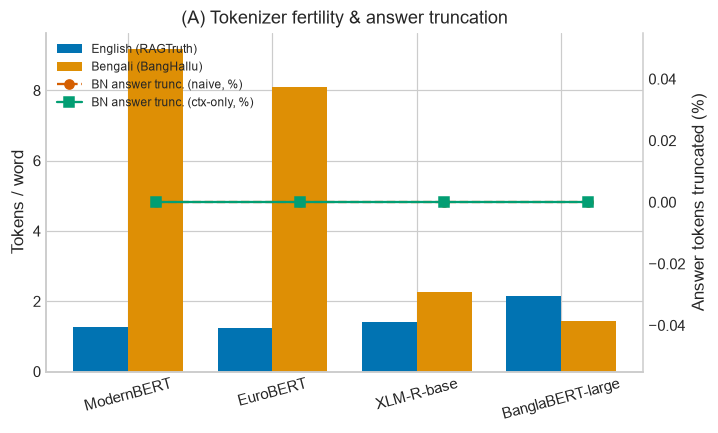

[figure] saved fig1a_tokenizer_fertility_preview.png/.pdf @300dpi


In [14]:
# Stage 1.7 — Tokenizer fertility & truncation audit  -> Table 1, Fig 1A
def words(s): return str(s).split()

def audit_tokenizer(label, name, max_len, en_df, bn_df, n=1500):
    tok = load_tokenizer(name); out = {}
    for lang, d in (("EN", en_df), ("BN", bn_df)):
        d = d.sample(min(n, len(d)), random_state=0) if d is not None and len(d) else None
        if d is None: out[lang] = dict(fertility=np.nan, trunc_ex=np.nan, naive_ans_trunc=np.nan, ctx_only_ans_trunc=np.nan); continue
        nw = sum(len(words(a)) for a in d["answer"]); nt = sum(len(tok(str(a), add_special_tokens=False)["input_ids"]) for a in d["answer"])
        enc = Encoder(tok, max_len, use_query=True)
        tr_ex = naive_lost = ctx_lost = tot_a = 0
        for q, c, a in zip(d["question"], d["context"], d["answer"]):
            q_, c_, a_ = str(q), str(c), str(a)
            n_ids = [len(tok(x, add_special_tokens=False)["input_ids"]) for x in (q_, c_, a_)]
            total = sum(n_ids) + tok.num_special_tokens_to_add(pair=True)
            tr_ex += int(total > max_len); tot_a += n_ids[2]
            # naive: tokenizer default longest_first on (Q+C, A) pair
            e = tok(q_ + " " + c_, a_, truncation="longest_first", max_length=max_len, return_tensors=None, return_offsets_mapping=False)
            try: kept_a = sum(1 for s in e.sequence_ids() if s == 1)
            except Exception: kept_a = n_ids[2]
            naive_lost += max(n_ids[2] - kept_a, 0)
            ctx_lost += enc.encode(q_, c_, a_)["ans_truncated_tokens"]
        out[lang] = dict(fertility=nt / max(nw, 1), trunc_ex=100 * tr_ex / len(d), naive_ans_trunc=100 * naive_lost / max(tot_a, 1), ctx_only_ans_trunc=100 * ctx_lost / max(tot_a, 1))
    del tok; gc.collect(); return out

AUDIT_MODELS = [("ModernBERT", MODELS["ModernBERT"], 4096), ("EuroBERT", MODELS["EuroBERT"], 4096), ("XLM-R-base", MODELS["XLM-R-base"], 512), ("BanglaBERT-large", MODELS["BanglaBERT-large"], 512)]
rag, bh = DATA.get("ragtruth"), DATA.get("banghallu")
en_audit = rag[rag.split == "test"] if rag is not None else None
bn_audit = bh[bh.split == "test"] if bh is not None else None
AUDIT = {}
if en_audit is not None and bn_audit is not None:
    for lbl, nm, ml in AUDIT_MODELS:
        try:
            AUDIT[lbl] = audit_tokenizer(lbl, nm, ml, en_audit, bn_audit); print(lbl, AUDIT[lbl])
        except Exception as e:
            print(f"[WARN] audit failed for {lbl}: {str(e)[:200]}")
    # also audit the 512-token views of the long-context models (what a 512-limited deployment would see)
    for lbl, nm in (("ModernBERT", MODELS["ModernBERT"]), ("EuroBERT", MODELS["EuroBERT"])):
        try: AUDIT[lbl + " @512"] = audit_tokenizer(lbl, nm, 512, en_audit, bn_audit)
        except Exception as e: print("[WARN]", e)

# Table 1: dataset statistics + fertility audit
def ds_stats(key, d):
    if d is None: return None
    sp = d["split"].value_counts().to_dict()
    ctx = float((d["context"].astype(str).str.len() > 0).mean())
    gran = "token/span + answer" if d["label_spans"].map(lambda x: len(x) > 0 if isinstance(x, list) else False).any() else "answer-level"
    lab = d["label_answer"].dropna(); pos = float(lab.mean()) if len(lab) else float("nan")
    return dict(Dataset=key, Train=sp.get("train", 0), Dev=sp.get("dev", 0), Test=sp.get("test", 0), **{"Context present (%)": round(100 * ctx, 1)},
                **{"Label granularity": gran, "Hallucinated (%)": round(100 * pos, 1) if not math.isnan(pos) else "--", "License": LICENSES.get(key, "--")})
t1a = pd.DataFrame([s for s in (ds_stats(k, v) for k, v in DATA.items()) if s])
t1b = pd.DataFrame([dict(Tokenizer=lbl, **{"Max len": (4096 if "@512" not in lbl and lbl in ("ModernBERT", "EuroBERT") else 512),
                    "Tokens/word EN": round(v["EN"]["fertility"], 3), "Tokens/word BN": round(v["BN"]["fertility"], 3),
                    "Examples truncated EN (%)": round(v["EN"]["trunc_ex"], 2), "Examples truncated BN (%)": round(v["BN"]["trunc_ex"], 2),
                    "Ans tokens truncated BN naive (%)": round(v["BN"]["naive_ans_trunc"], 3), "Ans tokens truncated BN ctx-only (%)": round(v["BN"]["ctx_only_ans_trunc"], 3)})
                    for lbl, v in AUDIT.items()])
# merge both blocks into one CSV/TeX with a Section column (exported tables stay single-file as required)
t1 = pd.concat([t1a.assign(Section="Dataset statistics"), t1b.assign(Section="Tokenizer fertility audit")], ignore_index=True)
t1 = t1[["Section"] + [c for c in t1.columns if c != "Section"]].fillna("--")
save_table(t1, "table1_dataset_and_fertility_audit", "Dataset statistics and tokenizer fertility / truncation audit (EN = RAGTruth test, BN = BangHallu test). Context-only truncation keeps 100\\% of answer tokens.",
           lower_better=["Tokens/word BN", "Ans tokens truncated BN ctx-only (%)"], group_col="Section")

def plot_fig1a(ax1):
    if not AUDIT: ax1.text(0.5, 0.5, "audit unavailable", ha="center"); return
    labs = [l for l in AUDIT if "@512" not in l]; x = np.arange(len(labs)); w = 0.38
    ax1.bar(x - w / 2, [AUDIT[l]["EN"]["fertility"] for l in labs], w, label="English (RAGTruth)", color=PALETTE[0])
    ax1.bar(x + w / 2, [AUDIT[l]["BN"]["fertility"] for l in labs], w, label="Bengali (BangHallu)", color=PALETTE[1])
    ax1.set_xticks(x); ax1.set_xticklabels(labs, rotation=15); ax1.set_ylabel("Tokens / word"); ax1.set_title("(A) Tokenizer fertility & answer truncation")
    ax2 = ax1.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
    ax2.plot(x + w / 2, [AUDIT[l]["BN"]["naive_ans_trunc"] for l in labs], "o--", color=PALETTE[3], label="BN answer trunc. (naive, %)")
    ax2.plot(x + w / 2, [AUDIT[l]["BN"]["ctx_only_ans_trunc"] for l in labs], "s-", color=PALETTE[2], label="BN answer trunc. (ctx-only, %)")
    ax2.set_ylabel("Answer tokens truncated (%)")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
fig, ax = plt.subplots(figsize=(7, 4)); plot_fig1a(ax); save_fig(fig, "fig1a_tokenizer_fertility_preview")

## Stage 2 — Experiment B: model zoo + source-domain sanity check on RAGTruth

In [15]:
# Stage 2.1 — model zoo: inference engine, scorers, trainer
import torch.nn.functional as F
from sklearn.utils import shuffle as sk_shuffle

def _sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def _autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(DEVICE == "cuda" and AMP_DTYPE != torch.float32))

@torch.no_grad()
def run_inference(model, enc, df, kind, bs):
    """kind: 'seq' (sequence classifier) or 'token' (per-answer-token hallucination prob; answer score = max pooling)."""
    # On an 8 GB GPU, batch=8 at 2k–4k tokens can OOM. Keep short-sequence
    # inference fast, but cap long-context inference to a safer batch size.
    if DEVICE == "cuda" and getattr(enc, "max_len", 512) >= 2048 and VRAM_GB < 12:
        bs = min(bs, 2)
    if DEVICE == "cuda" and VRAM_GB < 12:
        bs = max(1, min(bs, 8192 // max(getattr(enc, "max_len", 512), 1)))      # 8k padded tokens per forward pass at most
    model.eval()
    t0 = time.perf_counter()
    encs = [enc.encode(q, c, a) for q, c, a in zip(df["question"], df["context"], df["answer"])]
    enc_ms = (time.perf_counter() - t0) * 1000 / max(len(encs), 1)
    ids, labels = list(df["id"]), list(df["label_answer"])
    order = np.argsort([len(e["input_ids"]) for e in encs]); recs = [None] * len(encs)
    s = 0
    while s < len(order):
        idx = order[s:s + bs]; batch = [encs[i] for i in idx]
        try:
            inputs, ap = collate(batch, enc.pad)
            _sync(); t1 = time.perf_counter()
            with _autocast():
                logits = model(**inputs).logits
            _sync()
        except torch.cuda.OutOfMemoryError:
            inputs = ap = logits = None; free_gpu()
            if bs == 1: raise
            bs = max(bs // 2, 1); print(f"[infer] CUDA OOM -> batch size {bs}"); continue
        s += len(idx)
        dt = (time.perf_counter() - t1) * 1000 / len(idx) + enc_ms
        probs = torch.softmax(logits.float(), -1)[..., 1]
        for j, i in enumerate(idx):
            if kind == "seq":
                pp, toks = float(probs[j]), []
            else:
                toks = [round(float(x), 4) for x in probs[j][ap[j]].cpu().tolist()]; pp = pool_scores(toks, "max")
            recs[i] = dict(id=str(ids[i]), gold_label=int(labels[i]) if labels[i] is not None and not pd.isna(labels[i]) else -1,
                           pred_prob=pp, pred_label=0, token_probs=toks, latency_ms=float(dt))
    return recs


class HFScorer:
    def __init__(self, path, kind, max_len, norm_on=False, use_query=True):
        self.kind = kind
        self.tok = load_tokenizer(path)
        cls = AutoModelForSequenceClassification if kind == "seq" else AutoModelForTokenClassification
        kwargs = model_load_kwargs(path); dtype = AMP_DTYPE if DEVICE == "cuda" else torch.float32
        if str(path) == M2_CANDIDATES[0]:
            # released M2: config/weights from the M2 repo at its pinned revision, custom model code from EuroBERT at its pinned revision
            config = AutoConfig.from_pretrained(path, **kwargs)
            self.model = cls.from_pretrained(path, config=config, code_revision=EUROBERT_CODE_REVISION, torch_dtype=dtype, **kwargs)
        else:
            self.model = cls.from_pretrained(path, torch_dtype=dtype, **kwargs)
        self.model = self.model.to(DEVICE).eval()
        self.enc = Encoder(self.tok, max_len, get_normalizer(norm_on), use_query)
    def predict(self, df):
        return run_inference(self.model, self.enc, df, self.kind, INFER_BS)

def _tok_words(s):
    s = unicodedata.normalize("NFKC", str(s)).lower().translate(BN_DIGITS)
    return re.findall(r"\w+", s)

class LexicalScorer:
    """M0: lexical containment. Hallucination score = 1 - mean per-word support (exact word OR char-trigram coverage)."""
    def predict(self, df):
        recs = []
        for i, q, c, a, y in zip(df["id"], df["question"], df["context"], df["answer"], df["label_answer"]):
            t0 = time.perf_counter()
            cw = set(_tok_words(c)); ctext = " ".join(_tok_words(c)); tri = {ctext[k:k + 3] for k in range(len(ctext) - 2)}
            aw = _tok_words(a); toks = []
            for w in aw:
                if w in cw: toks.append(0.0); continue
                g = [w[k:k + 3] for k in range(max(len(w) - 2, 1))]
                cov = sum(x in tri for x in g) / len(g)
                toks.append(float(1 - cov))
            pp = float(np.mean(toks)) if toks else 0.0
            recs.append(dict(id=str(i), gold_label=int(y) if y is not None and not pd.isna(y) else -1, pred_prob=pp, pred_label=0,
                             token_probs=[round(t, 4) for t in toks], latency_ms=(time.perf_counter() - t0) * 1000))
        return recs

def make_items(enc, df, kind):
    items = []
    for q, c, a, y, sp in zip(df["question"], df["context"], df["answer"], df["label_answer"], df["label_spans"]):
        e = enc.encode(q, c, a); e["y"] = int(y)
        if kind == "token":
            sp = sp if isinstance(sp, list) else []
            e["tok_labels"] = [int(any(o[0] < s[1] and o[1] > s[0] for s in sp)) for o in e["ans_off"]]
        items.append(e)
    return items

def _make_batches(lengths, budget, max_ex, rng):
    """Length-bucketed dynamic batches under a padded-token budget."""
    idx = rng.permutation(len(lengths)); batches = []
    for s in range(0, len(idx), 256):
        cur, mx = [], 0
        for i in sorted(idx[s:s + 256], key=lambda j: lengths[j]):
            m = max(mx, lengths[i])
            if cur and (m * (len(cur) + 1) > budget or len(cur) >= max_ex):
                batches.append(cur); cur, m = [], lengths[i]
            cur.append(int(i)); mx = m
        if cur: batches.append(cur)
    return [batches[i] for i in rng.permutation(len(batches))]

def train_model(kind, backbone, train_df, dev_df, seed, out_dir, max_len=512, norm_on=False, use_query=True,
                epochs=5, lr=2e-5, loss_mode="ce", patience=4, min_epochs=4, tag="", optimizer_name=None):
    """kind: 'seq' | 'token'. loss_mode: 'ce' | 'mil'. optimizer_name: None (= OPTIMIZER_DEFAULT) | 'adamw_fused' | 'adamw8bit' | 'adamw'.
    8 GB-safe: the memory need is estimated BEFORE anything is moved to the GPU (and the optimizer is downgraded to 8-bit automatically if it
    would not fit), token-budget dynamic batches, gradient checkpointing only for large/long-context models, frozen huge embedding matrices,
    OOM back-off, and per-epoch resume files (interrupt freely; rerun the cell to continue). Finished if out_dir/config.json exists."""
    out_dir = Path(out_dir)
    if (out_dir / "config.json").exists():
        print(f"[train] {tag or out_dir.name}: checkpoint found, skipping"); return out_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    reset_gpu(); set_seed(seed); t_start = time.time()
    tok = load_tokenizer(backbone); enc = Encoder(tok, max_len, get_normalizer(norm_on), use_query)
    cls = AutoModelForSequenceClassification if kind == "seq" else AutoModelForTokenClassification
    model = cls.from_pretrained(backbone, num_labels=2, **model_load_kwargs(backbone))          # still on the CPU
    need_ckpt = VRAM_GB < 12 and ("large" in backbone.lower() or max_len >= 1024)
    if need_ckpt:
        try: model.gradient_checkpointing_enable()
        except Exception: pass
    if VRAM_GB < 12 and getattr(model.config, "vocab_size", 0) > 100000:    # XLM-R / EuroBERT: embeddings are ~70% of all parameters
        model.get_input_embeddings().weight.requires_grad = False
        if need_ckpt:
            try: model.enable_input_require_grads()
            except Exception: pass
    opt_name = optimizer_name or OPTIMIZER_DEFAULT
    if DEVICE == "cuda":                                                   # pre-flight: decide BEFORE touching the GPU
        n_tot = sum(p.numel() for p in model.parameters()); n_tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
        need = lambda nm: (n_tot * 4 + n_tr * (4 + (2 if nm == "adamw8bit" else 8)) + n_tot * 2) / 2**30 + 1.0   # fp32 weights + grads + opt state + bf16 weight cache + activations
        avail = gpu_avail_gb()
        if need(opt_name) > avail and opt_name != "adamw8bit":
            print(f"[train] {tag}: ~{need(opt_name):.1f} GB needed > {avail:.1f} GB available -> switching optimizer {opt_name} -> adamw8bit"); opt_name = "adamw8bit"
        print(f"[train] {tag}: params {n_tot / 1e6:.0f}M (trainable {n_tr / 1e6:.0f}M), need ~{need(opt_name):.1f} GB, available {avail:.1f} GB, optimizer={opt_name}")
        if need(opt_name) > avail:
            raise RuntimeError(f"Not enough free GPU memory ({avail:.1f} GB available, ~{need(opt_name):.1f} GB needed). Restart the kernel and close other GPU programs.")
    model = model.to(DEVICE)
    state = dict(budget=(1536 if "large" in backbone.lower() else 2048) if VRAM_GB < 12 else 8192)   # padded tokens per micro-batch; halves on CUDA OOM
    max_ex = 16
    items = make_items(enc, train_df, "token" if (kind == "token" and loss_mode == "ce") else "seq")
    n = len(items); lengths = [len(e["input_ids"]) for e in items]
    steps = max(math.ceil(n / EFFECTIVE_BS) * epochs, 1)
    nd = ["bias", "LayerNorm.weight", "layer_norm", "norm"]
    groups = [{"params": [p for nm, p in model.named_parameters() if p.requires_grad and not any(x in nm for x in nd)], "weight_decay": 0.01},
              {"params": [p for nm, p in model.named_parameters() if p.requires_grad and any(x in nm for x in nd)], "weight_decay": 0.0}]
    opt, opt_name = build_optimizer(groups, lr, opt_name)
    warm = max(int(0.1 * steps), 1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / warm, max((steps - s) / max(steps - warm, 1), 0.0)))
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and AMP_DTYPE == torch.float16))
    rng = np.random.default_rng(seed); best, best_state, bad, log, start_ep = -1e9, None, 0, [], 0
    infer_kind = "seq" if kind == "seq" else "token"
    rp, bp = out_dir / "_resume.pt", out_dir / "_best.pt"
    if rp.exists():
        ck = torch.load(rp, map_location="cpu", weights_only=False)
        if ck.get("opt_name") != opt_name:                              # resume file written with a different optimizer -> start clean
            print(f"[train] {tag}: discarding incompatible resume file"); rp.unlink()
        else:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            start_ep, best, bad, log = ck["epoch"], ck["best"], ck["bad"], ck["log"]; rng.bit_generator.state = ck["rng"]
            if bp.exists(): best_state = torch.load(bp, map_location="cpu")
            print(f"[train] {tag}: resuming after epoch {start_ep}")
        del ck
    tot = cnt = acc = 0

    def fwd_bwd(bidx):
        nonlocal tot, cnt, acc
        batch = [items[i] for i in bidx]; ok = True; inputs = ap = logits = loss = None
        try:
            inputs, ap = collate(batch, enc.pad, token_labels=[b["tok_labels"] for b in batch] if (kind == "token" and loss_mode == "ce") else None)
            y = torch.tensor([b["y"] for b in batch], device=DEVICE); lab_tok = inputs.pop("labels_tok", None)
            with _autocast():
                logits = model(**inputs).logits
            if kind == "seq":
                loss = F.cross_entropy(logits.float(), y)
            elif loss_mode == "ce":
                loss = F.cross_entropy(logits.float().view(-1, 2), lab_tok.view(-1), ignore_index=-100)
            else:
                p = torch.softmax(logits.float(), -1)[..., 1].masked_fill(~ap, 0.0).max(1).values.clamp(1e-6, 1 - 1e-6)
                loss = F.binary_cross_entropy(p, y.float())
            if torch.isnan(loss): return
            scaler.scale(loss * len(batch)).backward()
            tot += float(loss) * len(batch); cnt += len(batch); acc += len(batch)
        except torch.cuda.OutOfMemoryError:
            ok = False
        if not ok:
            inputs = ap = logits = loss = None; opt.zero_grad(set_to_none=True); acc = 0; reset_gpu()
            state["budget"] = max(state["budget"] // 2, 256); print(f"[train] CUDA OOM -> token budget {state['budget']}")
            if len(bidx) == 1: raise RuntimeError("OOM on a single example; lower max_len")
            h = len(bidx) // 2; fwd_bwd(bidx[:h]); fwd_bwd(bidx[h:])

    def do_step():
        nonlocal acc
        try:
            scaler.unscale_(opt)
            for p_ in model.parameters():
                if p_.grad is not None: p_.grad.div_(max(acc, 1))
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        except torch.cuda.OutOfMemoryError:
            reset_gpu(); state["budget"] = max(state["budget"] // 2, 256); print(f"[train] CUDA OOM at optimizer step -> skipped one update, token budget {state['budget']}")
        opt.zero_grad(set_to_none=True); acc = 0

    for ep in range(start_ep, epochs):
        model.train(); tot = cnt = acc = 0; t_ep = time.time()
        for bidx in _make_batches(lengths, state["budget"], max_ex, rng):
            fwd_bwd(bidx)
            if acc >= EFFECTIVE_BS: do_step()
        if acc > 0: do_step()
        recs = run_inference(model, enc, dev_df, infer_kind, INFER_BS)
        yd, pd_ = recs_arrays(recs); auc = safe_auc(yd, pd_); score = auc if not math.isnan(auc) else -tot / max(cnt, 1)
        log.append(dict(epoch=ep + 1, train_loss=tot / max(cnt, 1), dev_auroc=auc, dev_macro_f1_at_0p5=macro_f1(yd, (pd_ >= 0.5).astype(int))))
        print(f"[train] {tag} ep{ep + 1}/{epochs} loss={tot / max(cnt, 1):.4f} dev_auroc={auc:.4f} ({time.time() - t_ep:.0f}s) {gpu_status()}")
        if score > best + 1e-5:
            best, bad = score, 0; best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
            torch.save(best_state, bp)
        else:
            bad += 1
        tmp = out_dir / "_resume.tmp"
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep + 1, best=best, bad=bad, log=log,
                        rng=rng.bit_generator.state, opt_name=opt_name), tmp); os.replace(tmp, rp)
        if bad >= patience and ep + 1 >= min_epochs: break
    if best_state is not None: model.load_state_dict(best_state)
    model.to(AMP_DTYPE if DEVICE == "cuda" else torch.float32).save_pretrained(out_dir, safe_serialization=True)
    tok.save_pretrained(out_dir)
    json.dump(dict(log=log, seed=seed, backbone=backbone, kind=kind, loss_mode=loss_mode, n_train=n, epochs=epochs, lr=lr, optimizer=opt_name,
                   best_dev=best, seconds=time.time() - t_start, token_budget=state["budget"], grad_ckpt=need_ckpt), open(out_dir / "train_log.json", "w"), indent=1)
    for f in (rp, bp):
        if f.exists(): f.unlink()
    model = opt = best_state = scaler = sched = None      # release GPU memory
    reset_gpu(); return out_dir


def reachable(name):
    try: AutoConfig.from_pretrained(name, **model_load_kwargs(name)); return True
    except Exception as e: print(f"[reachable] {name}: {type(e).__name__}: {str(e)[:120]}"); return False

def resolve_first(cands):
    for c in cands:
        if reachable(c): return c
    return None

In [16]:
# Stage 2.2 — token/span metrics (RAGTruth)
def token_span_eval(df, recs, enc, tok_tau=0.5):
    tp = fp = fn = 0; s_pred = s_pred_hit = s_gold = s_gold_hit = 0
    for (_, r), rec in zip(df.iterrows(), recs):
        e = enc.encode(r["question"], r["context"], r["answer"])
        p = np.array(rec["token_probs"]) >= tok_tau
        sp = r["label_spans"] if isinstance(r["label_spans"], list) else []
        g = np.array([any(o[0] < s[1] and o[1] > s[0] for s in sp) for o in e["ans_off"]], bool)
        n = min(len(p), len(g)); p, g = p[:n], g[:n]
        tp += int((p & g).sum()); fp += int((p & ~g).sum()); fn += int((~p & g).sum())
        runs, i = [], 0
        while i < n:
            if p[i]:
                j = i
                while j + 1 < n and p[j + 1]: j += 1
                runs.append((e["ans_off"][i][0], e["ans_off"][j][1])); i = j + 1
            else: i += 1
        s_pred += len(runs); s_gold += len(sp)
        s_pred_hit += sum(any(a < s[1] and b > s[0] for s in sp) for a, b in runs)
        s_gold_hit += sum(any(a < s[1] and b > s[0] for a, b in runs) for s in sp)
    P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1); F = 2 * P * R / max(P + R, 1e-9)
    sP = s_pred_hit / max(s_pred, 1); sR = s_gold_hit / max(s_gold, 1); sF = 2 * sP * sR / max(sP + sR, 1e-9)
    return dict(token_p=P, token_r=R, token_f1=F, span_p=sP, span_r=sR, span_f1=sF)

### Released detector provenance and strict checkpoint policy

M1 is the official English ModernBERT-base LettuceDetect checkpoint. M2 is the official EuroBERT-210M Chinese RAGTruth fine-tune; the public release family is language-specific, and this notebook does not claim that a single generic multilingual M2 checkpoint exists. M2 is evaluated on its native Chinese translated-RAGTruth test set and then transferred to Bengali. The optional M2* is a separate EuroBERT-210M model trained by this study on English RAGTruth; it is disabled by default and must never be reported as released M2. Released checkpoint weights, the EuroBERT backbone weights, and EuroBERT custom code revisions are pinned in the configuration.

For security, `trust_remote_code=True` executes repository-provided model code. The EuroBERT code revision is pinned for reproducibility; review the model repository before use.

In [17]:
# Stage 2.3 — released M1/M2 source evaluation -> Table 2
from datasets import load_dataset

rag = DATA.get("ragtruth")
M1_PATH = resolve_first(M1_CANDIDATES) if rag is not None else None
M2_PATH = resolve_first(M2_CANDIDATES) if rag is not None else None
M2STAR_PATH = None
print("M1 released checkpoint:", M1_PATH)
print("M2 released checkpoint (Chinese RAGTruth fine-tune):", M2_PATH)

if rag is not None and REQUIRE_RELEASED_M1 and M1_PATH is None:
    raise RuntimeError(
        "Required released M1 checkpoint is unavailable. Expected " + M1_CANDIDATES[0] +
        ". Check internet/Hugging Face access. No substitute model will be trained silently."
    )
if rag is not None and REQUIRE_RELEASED_M2 and M2_PATH is None:
    raise RuntimeError(
        "Required released M2 checkpoint is unavailable. Expected " + M2_CANDIDATES[0] +
        ". Check internet/Hugging Face access. No EuroBERT fallback will be trained in the M2 slot."
    )

def ensure_m2_path():
    """Return the released M2 checkpoint only; never train a replacement silently."""
    if M2_PATH is not None:
        return M2_PATH
    if REQUIRE_RELEASED_M2:
        raise RuntimeError("Released M2 is required but unavailable; refusing to substitute M2*.")
    return None


def _span_list(value):
    """Convert RAGTruth annotations into character-span tuples."""
    if value is None:
        return []

    # Critical fix: Hugging Face List(struct) can become a NumPy array.
    if isinstance(value, np.ndarray):
        value = value.tolist()
    elif isinstance(value, pd.Series):
        value = value.tolist()

    if isinstance(value, str):
        try:
            value = json.loads(value)
        except Exception:
            return []

    if isinstance(value, dict):
        value = [value]

    if not isinstance(value, (list, tuple)):
        return []

    out = []
    for item in value:
        if not isinstance(item, dict):
            continue
        try:
            start = int(item["start"])
            end = int(item["end"])
            if end > start >= 0:
                out.append((start, end))
        except (KeyError, TypeError, ValueError):
            continue

    return out


def load_m2_native_test():
    """Load the published M2 model's native Chinese translated-RAGTruth test split."""
    ds = load_dataset(M2_SOURCE_DATASET)
    if "test" not in ds:
        raise RuntimeError(f"{M2_SOURCE_DATASET} has no test split; available splits: {list(ds.keys())}")
    raw = ds["test"].to_pandas()
    required = {"prompt", "answer", "labels"}
    missing = required - set(raw.columns)
    if missing:
        raise RuntimeError(f"Unexpected schema for {M2_SOURCE_DATASET}; missing {sorted(missing)}, found {list(raw.columns)}")
    rows = []
    for i, row in raw.iterrows():
        spans = _span_list(row["labels"])
        prompt = "" if pd.isna(row["prompt"]) else str(row["prompt"])
        answer = "" if pd.isna(row["answer"]) else str(row["answer"])
        rows.append({"id": f"ragtruth-cn-test-{i}", "question": "", "context": prompt, "answer": answer,
                     "label_answer": int(bool(spans)), "label_spans": spans, "split": "test"})
    out = pd.DataFrame(rows)
    if out.empty or out["label_answer"].nunique() < 2:
        raise RuntimeError("M2 native Chinese test set loaded without both classes; inspect its labels before evaluating.")
    print(f"M2 native source data: {M2_SOURCE_DATASET} test n={len(out)}, hallucinated={int(out.label_answer.sum())}")
    return out

T2_ROWS, SOURCE_F1 = [], {}
if rag is not None:
    rag_en_test = rag[rag.split == "test"].reset_index(drop=True)
    m2_cn_test = load_m2_native_test() if M2_PATH is not None else None
    source_specs = [
        ("M1", M1_PATH, rag_en_test, "RAGTruth English (released M1 training language)"),
        ("M2", M2_PATH, m2_cn_test, "RAGTruth-CN translated Chinese (released M2 training language)"),
    ]
    if RUN_M2STAR_SUPPLEMENTARY:
        tr = rag[rag.split == "train"].copy()
        dev_mask = tr["context"].map(qhash) % 20 == 0
        out = train_model("token", M2STAR_BACKBONE, tr[~dev_mask], tr[dev_mask].head(400), seed=42,
                          out_dir=CKPT / "M2STAR_eurobert_ragtruth_en", max_len=2048,
                          norm_on=False, use_query=False, epochs=M2STAR_EPOCHS, lr=2e-5,
                          loss_mode="ce", tag="M2STAR-English-RAGTruth")
        M2STAR_PATH = str(out)
        source_specs.append(("M2STAR", M2STAR_PATH, rag_en_test,
                             "RAGTruth English (M2* trained on English RAGTruth)"))
    for mk, path, src_df, src_label in source_specs:
        if path is None or src_df is None:
            print(f"[WARN] {mk} source evaluation unavailable; no substitute checkpoint or dataset will be used")
            continue
        exp = "B_source_en" if mk in ("M1", "M2STAR") else "B_source_cn"
        lz = Lazy(lambda p=path: HFScorer(p, "token", 4096, False, False), key=f"{mk}_source")
        with lz:
            recs = cached_predict(exp, mk, 0, src_df, lz, tau=0.5)
            y, p = recs_arrays(recs)
            mets = full_metrics(y, p, 0.5)
            enc = lz.get().enc if lz.obj is not None else Encoder(load_tokenizer(path), 4096, use_query=False)
            ts = token_span_eval(src_df, recs, enc)
        SOURCE_F1[mk] = mets["macro_f1"]
        display_name = {
            "M1": "M1 — released English LettuceDetect (ModernBERT-base)",
            "M2": "M2 — released EuroBERT-210M LettuceDetect (Chinese RAGTruth fine-tune)",
            "M2STAR": "M2* — EuroBERT-210M fine-tuned by this study on English RAGTruth",
        }[mk]
        T2_ROWS.append({"Model": display_name, "Source test set": src_label,
                        "Token Precision": ts["token_p"], "Token Recall": ts["token_r"], "Token F1": ts["token_f1"],
                        "Span Precision": ts["span_p"], "Span Recall": ts["span_r"], "Span F1": ts["span_f1"],
                        "Answer Macro-F1": mets["macro_f1"], "AUROC": mets["auroc"], "N": mets["n"]})
    if T2_ROWS:
        t2 = pd.DataFrame(T2_ROWS)
        save_table(t2, "table2_native_source_evaluation",
                   "Native-language source-test evaluation: released English M1 on English RAGTruth; released Chinese-fine-tuned M2 on translated Chinese RAGTruth; optional M2* on English RAGTruth. Threshold fixed at 0.5. Source scores are language-specific and should not be interpreted as a same-language head-to-head comparison.",
                   higher_better=[c for c in t2.columns if c not in ("Model", "Source test set", "N")])
    else:
        print("[WARN] No source-domain models available -> Table 2 skipped")
else:
    print("[WARN] RAGTruth unavailable -> Table 2 skipped")


config.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

configuration_eurobert.py: 0.00B [00:00, ?B/s]

M1 released checkpoint: KRLabsOrg/lettucedect-base-modernbert-en-v1
M2 released checkpoint (Chinese RAGTruth fine-tune): KRLabsOrg/lettucedect-210m-eurobert-cn-v1


README.md: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


... (16 outputs left out)

configuration_eurobert.py: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/847M [00:00<?, ?B/s]

[table] saved table2_native_source_evaluation.csv/.tex (2 rows)


## Stage 3 — Experiments C & D: cross-lingual transfer to Bengali (M0, released M1, released Chinese-fine-tuned M2; optional M2*)

In [18]:
# Stage 3.1 — shared evaluation helpers
def tau_key(model_key, seed): return f"{model_key}_seed{seed}"

def run_dev_test(model_key, seed, lazy, dev_df, test_df, exp_dev, exp_test):
    """Tune tau* strictly on dev, freeze it, evaluate on test. Returns (metrics, dev_recs, test_recs, tau)."""
    rd = cached_predict(exp_dev, model_key, seed, dev_df, lazy, 0.5)
    yd, pdv = recs_arrays(rd); tau = tune_tau(yd, pdv); set_tau(tau_key(model_key, seed), tau)
    rt_ = cached_predict(exp_test, model_key, seed, test_df, lazy, tau)
    yt, pt = recs_arrays(rt_); m = full_metrics(yt, pt, tau); m["tau"] = tau
    m["latency_ms"] = float(np.mean([r["latency_ms"] for r in rt_])); m["peak_vram_mb"] = RESOURCES.get(model_key, {}).get("peak_vram_mb", float("nan"))
    return m, rd, rt_, tau

bh = DATA.get("banghallu")
assert bh is not None, "BangHallu is required for Stages 3-5. Provide it under ./data/raw/banghallu*"
BH_TRAIN = bh[bh.split == "train"].reset_index(drop=True)
BH_DEV = bh[bh.split == "dev"].reset_index(drop=True)
BH_TEST = bh[bh.split == "test"].reset_index(drop=True)
print("BangHallu", len(BH_TRAIN), len(BH_DEV), len(BH_TEST), "| test hallucinated %:", round(100 * BH_TEST.label_answer.mean(), 1))

BangHallu 5627 1238 1228 | test hallucinated %: 50.0


In [19]:
# Stage 3.2 — M0 / M1 / M2 on BangHallu (dev -> tau*, test frozen)
FROZEN = {}      # model key -> dict(metrics, dev_recs, test_recs)
frozen_specs = [("M0", lambda: LexicalScorer()),
                ("M1", lambda: HFScorer(M1_PATH, "token", 4096, False, True)),
                ("M2", lambda: HFScorer(ensure_m2_path(), "token", 4096, False, True))]
if RUN_M2STAR_SUPPLEMENTARY and M2STAR_PATH is not None:
    frozen_specs.append(("M2STAR", lambda: HFScorer(M2STAR_PATH, "token", 4096, False, True)))
for mk, factory in frozen_specs:
    if (mk == "M1" and M1_PATH is None) or (mk == "M2" and M2_PATH is None) or (mk == "M2STAR" and M2STAR_PATH is None):
        raise RuntimeError(f"Required model path missing for {mk}; refusing to substitute a different model.")
    res_key = mk if mk == "M0" else f"{mk}_bn"
    with Lazy(factory, key=res_key) as lz:
        m, rd, rt_, tau = run_dev_test(mk, 0, lz, BH_DEV, BH_TEST, "C_dev", "C_test")
    m["peak_vram_mb"] = RESOURCES.get(res_key, {}).get("peak_vram_mb", float("nan"))
    FROZEN[mk] = dict(metrics=m, dev=rd, test=rt_, tau=tau)
    print(mk, {k: round(v, 4) if isinstance(v, float) else v for k, v in m.items()})

M0 {'macro_f1': 0.653, 'precision': 0.6212, 'recall': 0.8388, 'auroc': 0.5943, 'auprc': 0.5336, 'ece': 0.4287, 'accuracy': 0.6637, 'n': 1228, 'tau': 0.0059, 'latency_ms': 0.0873, 'peak_vram_mb': 8.125}
M1 {'macro_f1': 0.5335, 'precision': 0.5345, 'recall': 0.7068, 'auroc': 0.5464, 'auprc': 0.5275, 'ece': 0.4457, 'accuracy': 0.5456, 'n': 1228, 'tau': 0.0032, 'latency_ms': 12.0931, 'peak_vram_mb': 587.8799}
M2 {'macro_f1': 0.5083, 'precision': 0.5093, 'recall': 0.5782, 'auroc': 0.5115, 'auprc': 0.5139, 'ece': 0.3006, 'accuracy': 0.5106, 'n': 1228, 'tau': 0.4199, 'latency_ms': 7.1019, 'peak_vram_mb': 674.521}


In [20]:
# Stage 3.3 — Table 3
NAMES = {"M0": "M0 Lexical containment", "M1": "M1 released English LettuceDetect (ModernBERT)", "M2": "M2 released EuroBERT-210M LettuceDetect (Chinese RAGTruth fine-tune)", "M2STAR": "M2* EuroBERT-210M fine-tuned on English RAGTruth"}
rows = []
for mk, v in FROZEN.items():
    y, p = recs_arrays(v["test"]); pred = (p >= v["tau"]).astype(int); lo, hi = bootstrap_ci_single(y, pred)
    m = v["metrics"]
    rows.append({"Model": NAMES[mk],
                 "Native source test set": {"M1": "RAGTruth English", "M2": "RAGTruth-CN translated Chinese", "M2STAR": "RAGTruth English (study-trained)"}.get(mk, "n/a"),
                 "Macro-F1": m["macro_f1"], "95% CI": f"[{lo:.3f}, {hi:.3f}]", "Precision": m["precision"], "Recall": m["recall"],
                 "AUROC": m["auroc"], "AUPRC": m["auprc"], "ECE": m["ece"], "Latency ms/ex": m["latency_ms"], "Peak VRAM MB": m["peak_vram_mb"],
                 "tau*": m["tau"], "Native source-test Macro-F1": SOURCE_F1.get(mk, float("nan")),
                 "Δ Native source→BN": (m["macro_f1"] - SOURCE_F1[mk]) if mk in SOURCE_F1 else float("nan")})
t3 = pd.DataFrame(rows)
save_table(t3, "table3_cross_lingual_transfer", "Frozen model weights transferred to Bengali (BangHallu test); tau* tuned on BangHallu dev only and frozen. Native-source scores use English RAGTruth for M1/M2* and translated Chinese RAGTruth for released M2, so source-language scores must be interpreted by source set.",
           higher_better=["Macro-F1", "Precision", "Recall", "AUROC", "AUPRC"], lower_better=["ECE", "Latency ms/ex", "Peak VRAM MB"])

[table] saved table3_cross_lingual_transfer.csv/.tex (3 rows)


,Model,Native source test set,Macro-F1,95% CI,Precision,Recall,AUROC,AUPRC,ECE,Latency ms/ex,Peak VRAM MB,tau*,Native source-test Macro-F1,Δ Native source→BN
0,M0 Lexical containment,n/a,0.653045,"[0.624, 0.679]",0.621230,0.838762,0.594334,0.533587,0.428684,0.087322,8.125000,0.00593,NaN,NaN
1,M1 released English LettuceDetect (ModernBERT),RAGTruth English,0.533474,"[0.506, 0.562]",0.534483,0.706840,0.546363,0.527456,0.445675,12.093085,587.879883,0.00320,0.773131,-0.239657
2,M2 released EuroBERT-210M LettuceDetect (Chine...,RAGTruth-CN translated Chinese,0.508340,"[0.482, 0.536]",0.509326,0.578176,0.511532,0.513854,0.300593,7.101928,674.520996,0.41988,0.745523,-0.237183


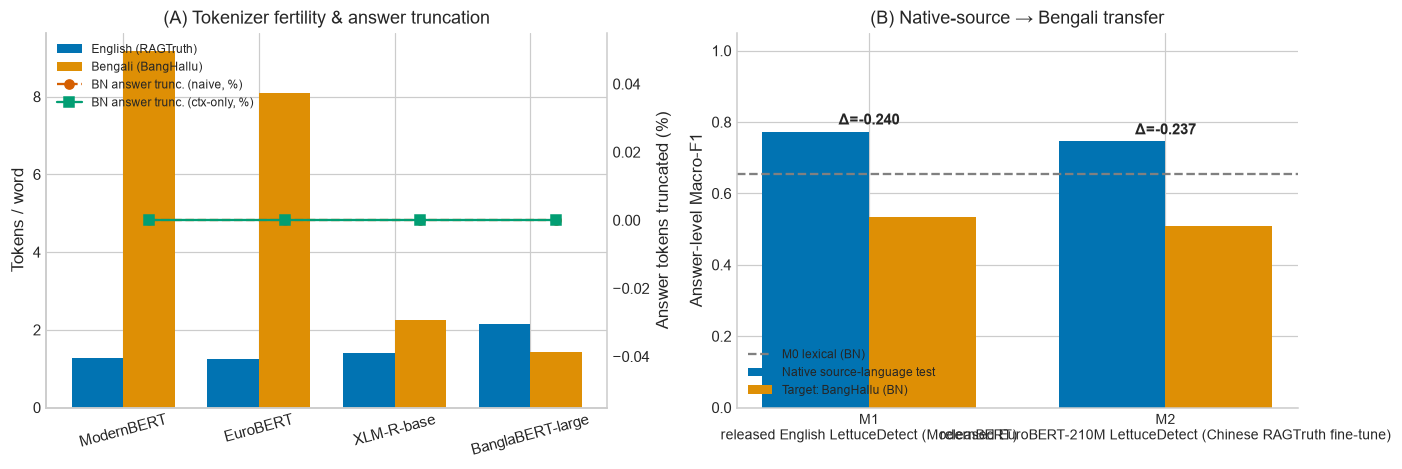

[figure] saved fig1_tokenizer_fertility_and_transfer_drop.png/.pdf @300dpi


In [21]:
# Stage 3.4 — Figure 1 (A: fertility & truncation, B: source→Bengali transfer drop)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_fig1a(axes[0])
ax = axes[1]; mods = [m for m in ("M1", "M2", "M2STAR") if m in FROZEN]; x = np.arange(len(mods)); w = 0.36
src = [SOURCE_F1.get(m, np.nan) for m in mods]; tgt = [FROZEN[m]["metrics"]["macro_f1"] for m in mods]
ax.bar(x - w / 2, src, w, color=PALETTE[0], label="Native source-language test"); ax.bar(x + w / 2, tgt, w, color=PALETTE[1], label="Target: BangHallu (BN)")
for i, (s_, t_) in enumerate(zip(src, tgt)):
    if not np.isnan(s_): ax.annotate(f"Δ={t_ - s_:+.3f}", (i, max(s_, t_) + 0.02), ha="center", fontsize=10, fontweight="bold")
if "M0" in FROZEN: ax.axhline(FROZEN["M0"]["metrics"]["macro_f1"], color="gray", ls="--", label="M0 lexical (BN)")
ax.set_xticks(x); ax.set_xticklabels([NAMES[m].split(" ", 1)[0] + "\n" + NAMES[m].split(" ", 1)[1] for m in mods], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("Answer-level Macro-F1"); ax.set_title("(B) Native-source → Bengali transfer"); ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); save_fig(fig, "fig1_tokenizer_fertility_and_transfer_drop")

## Stage 4 — Experiment E: low-resource Bengali adaptation (M3 XLM-R-base, M4 BanglaBERT-large + normalizer)

In [22]:
# Stage 4.1 — grouped sub-sampling, checkpoint management
def gkey(df):
    return df["question"].astype(str).where(df["question"].astype(str).str.len() > 0, df["context"].astype(str).str[:200])

def subsample_grouped(df, frac, seed, min_groups=20):
    """Question-grouped sub-sample: paired positive/negative answers of one question always stay together."""
    g = gkey(df); qs = sorted(g.unique(), key=lambda q: qhash(str(q) + f"|{seed}"))
    k = min(len(qs), max(int(math.ceil(frac * len(qs))), min_groups))
    keep = set(qs[:k]); return df[g.isin(keep)].reset_index(drop=True)

# Per-model recipes. M4 (BanglaBERT) learned well under r1 and its results are kept as they are.
# M3 (XLM-R) stayed at chance under r1 (loss ~0.693), so it is retrained once under r2 (longer, higher lr, frozen embeddings, patience 4).
M34 = {"M3": dict(backbone=MODELS["XLM-R-base"], norm=False, lr=3e-5), "M4": dict(backbone=MODELS["BanglaBERT-large"], norm=True, lr=1.5e-5)}
EPOCHS = {"M3": {0.10: 12, 0.25: 10, 1.0: 8}, "M4": {0.10: 10, 0.25: 8, 1.0: 5}}
RECIPES = {"M3": "r2", "M4": "r1"}

def archive_stale_recipe(model):
    """Move checkpoints/predictions produced under an older recipe aside (once) so they are never mixed with the new recipe."""
    marker = RES / "recipes.json"; cur = json.loads(marker.read_text()) if marker.exists() else {}
    if cur.get(model, "r1") == RECIPES[model]: return
    dst = ROOT / f"_stale_{model}_{cur.get(model, 'r1')}"; dst.mkdir(exist_ok=True); moved = 0
    for p in list(CKPT.glob(f"{model}-*")) + list(PRED.glob(f"*_{model}-*")):      # E_*, F_olik_*, G_* ... every prediction file of this model
        t = dst / p.name
        if t.exists(): t = dst / (p.name + f".{int(time.time())}")
        shutil.move(str(p), str(t)); moved += 1
    cur[model] = RECIPES[model]; marker.write_text(json.dumps(cur)); print(f"[recipe] {model}: archived {moved} files from the old recipe to {dst}")
for _m in M34: archive_stale_recipe(_m)

def mkey(m, frac, suffix=""): return f"{m}-{int(round(frac * 100))}pct{suffix}"
def ckpt_dir(key, seed): return CKPT / f"{key}_seed{seed}"

def ensure_ckpt(m, frac, seed, use_query=True, suffix="", optimizer_name=None):
    key = mkey(m, frac, suffix); out = ckpt_dir(key, seed)
    if (out / "config.json").exists(): return out
    spec = M34[m]
    tr = subsample_grouped(BH_TRAIN, frac, seed); dv = subsample_grouped(BH_DEV, frac, seed, min_groups=50) if frac < 1 else BH_DEV
    return train_model("seq", spec["backbone"], tr, dv, seed, out, max_len=512, norm_on=spec["norm"], use_query=use_query,
                       epochs=EPOCHS[m][frac], lr=spec["lr"], tag=f"{key}_s{seed}", optimizer_name=optimizer_name)

def seq_scorer(m, path, use_query=True):
    return HFScorer(str(path), "seq", 512, M34[m]["norm"], use_query)


[recipe] M3: archived 33 files from the old recipe to _stale_M3_r1


In [23]:
# Stage 4.2 — supervision curve across seeds
STAGE4 = {}      # (model, frac) -> list of per-seed dicts
for m in ("M3", "M4"):
    for frac in FRACTIONS:
        key = mkey(m, frac); STAGE4[(m, frac)] = []
        for seed in SEEDS:
            dv = BH_DEV if frac in (0.0, 1.0) else subsample_grouped(BH_DEV, frac, seed, min_groups=50)
            done = pred_path("E_dev", key, seed).exists() and pred_path("E_test", key, seed).exists()
            if frac == 0.0:
                def factory(m=m, seed=seed):
                    set_seed(seed); return seq_scorer(m, M34[m]["backbone"])        # untrained (random-init head) => no-supervision control
            else:
                if not done: ensure_ckpt(m, frac, seed)
                factory = (lambda m=m, key=key, seed=seed: seq_scorer(m, ckpt_dir(key, seed)))
            with Lazy(factory, key=key) as lz:
                met, rd, rt_, tau = run_dev_test(key, seed, lz, dv, BH_TEST, "E_dev", "E_test")
            met["peak_vram_mb"] = RESOURCES.get(key, {}).get("peak_vram_mb", float("nan"))
            STAGE4[(m, frac)].append(dict(seed=seed, metrics=met, test=rt_, tau=tau, n_train=len(subsample_grouped(BH_TRAIN, frac, seed)) if frac > 0 else 0))
            print(f"{key} seed={seed} F1={met['macro_f1']:.4f} AUROC={met['auroc']:.4f} tau={tau:.3f}")
            if not SAVE_CKPT and frac in (0.10, 0.25) and ckpt_dir(key, seed).exists():
                shutil.rmtree(ckpt_dir(key, seed), ignore_errors=True)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


M3-0pct seed=42 F1=0.5169 AUROC=0.5171 tau=0.415


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


M3-0pct seed=1337 F1=0.5104 AUROC=0.5143 tau=0.502


... (52 outputs left out)

Token indices sequence length is longer than the specified maximum sequence length for this model (1007 > 512). Running this sequence through the model will result in indexing errors


[train] M3-100pct_s2026 ep1/8 loss=0.6980 dev_auroc=0.5040 (32s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep2/8 loss=0.6965 dev_auroc=0.4926 (31s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep3/8 loss=0.6974 dev_auroc=0.5091 (31s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep4/8 loss=0.6956 dev_auroc=0.5101 (32s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep5/8 loss=0.6958 dev_auroc=0.5174 (32s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep6/8 loss=0.6962 dev_auroc=0.5040 (32s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep7/8 loss=0.6952 dev_auroc=0.4939 (33s) [gpu alloc 1.7 / peak 3.1 GB]
[train] M3-100pct_s2026 ep8/8 loss=0.6953 dev_auroc=0.4977 (32s) [gpu alloc 1.7 / peak 3.1 GB]


The tokenizer you are loading from 'checkpoints\M3-100pct_seed2026' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (522 > 512). Running this sequence through the model will result in indexing errors


M3-100pct seed=2026 F1=0.4404 AUROC=0.5096 tau=0.488
M4-0pct seed=42 F1=0.4779 AUROC=0.4759 tau=0.440
M4-0pct seed=1337 F1=0.5178 AUROC=0.5387 tau=0.496
M4-0pct seed=2026 F1=0.5058 AUROC=0.5153 tau=0.485
M4-10pct seed=42 F1=0.7980 AUROC=0.8738 tau=0.089
M4-10pct seed=1337 F1=0.7810 AUROC=0.8590 tau=0.142
M4-10pct seed=2026 F1=0.7456 AUROC=0.8256 tau=0.029
M4-25pct seed=42 F1=0.7969 AUROC=0.9050 tau=0.238
M4-25pct seed=1337 F1=0.7809 AUROC=0.8790 tau=0.443
M4-25pct seed=2026 F1=0.7783 AUROC=0.8921 tau=0.816
M4-100pct seed=42 F1=0.8329 AUROC=0.9315 tau=0.175
M4-100pct seed=1337 F1=0.8379 AUROC=0.9390 tau=0.575
M4-100pct seed=2026 F1=0.8243 AUROC=0.9290 tau=0.792


In [24]:
# Stage 4.3 — Table 4
rows = []
for (m, frac), lst in STAGE4.items():
    if not lst: continue
    f1s = [d["metrics"]["macro_f1"] for d in lst]
    preds = [np.array([int(r["pred_prob"] >= d["tau"]) for r in d["test"]]) for d in lst]
    lo, hi = bootstrap_ci_multiseed(np.array([r["gold_label"] for r in lst[0]["test"]]), preds)
    rows.append({"Model": {"M3": "M3 XLM-R-base", "M4": "M4 BanglaBERT-large + normalizer"}[m], "Supervision (%)": int(round(frac * 100)),
                 "Train examples": int(np.mean([d["n_train"] for d in lst])), "Seeds": len(lst),
                 "Macro-F1 (mean ± SD)": mean_sd(f1s), "95% Bootstrap CI": f"[{lo:.3f}, {hi:.3f}]",
                 "AUROC (mean ± SD)": mean_sd([d["metrics"]["auroc"] for d in lst]), "Precision (mean ± SD)": mean_sd([d["metrics"]["precision"] for d in lst]),
                 "Recall (mean ± SD)": mean_sd([d["metrics"]["recall"] for d in lst]), "ECE (mean ± SD)": mean_sd([d["metrics"]["ece"] for d in lst]),
                 "_f1_mean": float(np.mean(f1s))})
t4 = pd.DataFrame(rows)
t4_out = t4.drop(columns=["_f1_mean"])
save_table(t4_out, "table4_low_resource_adaptation", "Low-resource Bengali adaptation on BangHallu test: mean ± SD over seeds and 95\\% paired bootstrap CI of the seed-averaged Macro-F1 (supervision 0\\% = untrained head control).",
           higher_better=["Macro-F1 (mean ± SD)", "AUROC (mean ± SD)", "Precision (mean ± SD)", "Recall (mean ± SD)"], lower_better=["ECE (mean ± SD)"], group_col="Supervision (%)")

[table] saved table4_low_resource_adaptation.csv/.tex (8 rows)


,Model,Supervision (%),Train examples,Seeds,Macro-F1 (mean ± SD),95% Bootstrap CI,AUROC (mean ± SD),Precision (mean ± SD),Recall (mean ± SD),ECE (mean ± SD)
0,M3 XLM-R-base,0,0,3,0.503 ± 0.019,"[0.487, 0.516]",0.504 ± 0.019,0.502 ± 0.020,0.499 ± 0.036,0.056 ± 0.043
1,M3 XLM-R-base,10,564,3,0.506 ± 0.027,"[0.489, 0.523]",0.539 ± 0.021,0.528 ± 0.022,0.423 ± 0.187,0.013 ± 0.003
2,M3 XLM-R-base,25,1408,3,0.561 ± 0.053,"[0.542, 0.580]",0.585 ± 0.070,0.569 ± 0.057,0.517 ± 0.062,0.053 ± 0.020
3,M3 XLM-R-base,100,5627,3,0.502 ± 0.054,"[0.484, 0.521]",0.528 ± 0.018,0.523 ± 0.026,0.623 ± 0.168,0.015 ± 0.002
4,M4 BanglaBERT-large + normalizer,0,0,3,0.501 ± 0.020,"[0.487, 0.514]",0.510 ± 0.032,0.501 ± 0.021,0.454 ± 0.056,0.028 ± 0.029
5,M4 BanglaBERT-large + normalizer,10,564,3,0.775 ± 0.027,"[0.755, 0.794]",0.853 ± 0.025,0.749 ± 0.035,0.833 ± 0.030,0.154 ± 0.050
6,M4 BanglaBERT-large + normalizer,25,1408,3,0.785 ± 0.010,"[0.767, 0.803]",0.892 ± 0.013,0.780 ± 0.041,0.807 ± 0.104,0.096 ± 0.015
7,M4 BanglaBERT-large + normalizer,100,5627,3,0.832 ± 0.007,"[0.814, 0.850]",0.933 ± 0.005,0.846 ± 0.030,0.815 ± 0.051,0.117 ± 0.007


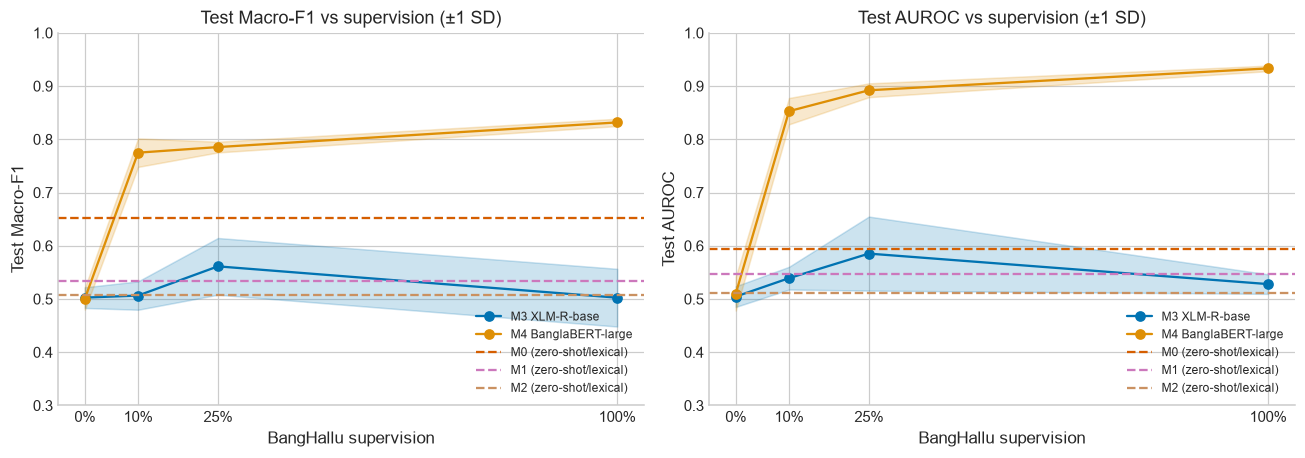

[figure] saved fig2_low_resource_adaptation_curve.png/.pdf @300dpi
Best adapted model on test (for downstream plots): M4


In [25]:
# Stage 4.4 — Figure 2
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3)); xs = [int(round(f * 100)) for f in FRACTIONS]
for ai, (met, title) in enumerate((("macro_f1", "Test Macro-F1"), ("auroc", "Test AUROC"))):
    ax = axes[ai]
    for ci, (m, lbl) in enumerate((("M3", "M3 XLM-R-base"), ("M4", "M4 BanglaBERT-large"))):
        mu = np.array([np.mean([d["metrics"][met] for d in STAGE4[(m, f)]]) for f in FRACTIONS])
        sd = np.array([np.std([d["metrics"][met] for d in STAGE4[(m, f)]], ddof=1) if len(STAGE4[(m, f)]) > 1 else 0.0 for f in FRACTIONS])
        ax.plot(xs, mu, "o-", color=PALETTE[ci], label=lbl); ax.fill_between(xs, mu - sd, mu + sd, color=PALETTE[ci], alpha=0.2)
    for bi, mk in enumerate(("M0", "M1", "M2")):
        if mk in FROZEN: ax.axhline(FROZEN[mk]["metrics"][met], ls="--", color=PALETTE[3 + bi], label=f"{mk} (zero-shot/lexical)")
    ax.set_xticks(xs); ax.set_xticklabels([f"{x}%" for x in xs]); ax.set_xlabel("BangHallu supervision"); ax.set_ylabel(title); ax.set_title(f"{title} vs supervision (±1 SD)")
    ax.set_ylim(0.3 if met == "macro_f1" else 0.3, 1.0); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save_fig(fig, "fig2_low_resource_adaptation_curve")
BEST_ADAPTED = max([("M3", 1.0), ("M4", 1.0)], key=lambda k: np.mean([d["metrics"]["macro_f1"] for d in STAGE4[k]]))[0]
print("Best adapted model on test (for downstream plots):", BEST_ADAPTED)

## Stage 5 — Experiment F & ablations: external generalization (Olikbochon), pooling, query conditioning, M5 (MIL), M6 (4-bit LLM)

In [26]:
# Stage 5.1 — Olikbochon frozen transfer (no re-tuning of weights or thresholds)
olik = DATA.get("olikbochon")
OLIK = None
if olik is not None:
    # Kaggle's blind competition test split has no labels and is dropped by ensure_labels; the natively labelled (train) rows serve as the
    # external, never-trained-on evaluation set (frozen weights and thresholds).
    OLIK = olik.reset_index(drop=True)
if OLIK is not None and not OLIK["label_answer"].notna().all():
    print("[WARN] Olikbochon has no native labels -> Experiment F is skipped (no synthetic labels are generated for blind test data).")
    OLIK = None
if OLIK is not None:
    OLIK["label_answer"] = OLIK["label_answer"].astype(int)
    print("Olikbochon eval:", len(OLIK), "hallucinated %:", round(100 * OLIK.label_answer.mean(), 1))

F_RES = {}   # model label -> dict(bh_f1, olik_f1, n)
def eval_frozen_on(key, seed, lazy, df, exp):
    tau = THRESHOLDS[tau_key(key, seed)]               # tau from BangHallu dev, never re-tuned
    recs = cached_predict(exp, key, seed, df, lazy, tau); y, p = recs_arrays(recs)
    m = full_metrics(y, p, tau); m["latency_ms"] = float(np.mean([r["latency_ms"] for r in recs])); return m, recs

if OLIK is not None:
    # M0-M2 (seed 0)
    external_specs = [("M0", lambda: LexicalScorer(), "M0"), ("M1", lambda: HFScorer(M1_PATH, "token", 4096, False, True), "M1_bn"),
                      ("M2", lambda: HFScorer(ensure_m2_path(), "token", 4096, False, True), "M2_bn")]
    if RUN_M2STAR_SUPPLEMENTARY and M2STAR_PATH is not None:
        external_specs.append(("M2STAR", lambda: HFScorer(M2STAR_PATH, "token", 4096, False, True), "M2STAR_bn"))
    for mk, factory, rk in external_specs:
        if mk not in FROZEN: continue
        with Lazy(factory, key=rk + "_olik") as lz:
            m, recs = eval_frozen_on(mk, 0, lz, OLIK, "F_olik")
        F_RES[mk] = dict(bh=[FROZEN[mk]["metrics"]["macro_f1"]], ol=[m["macro_f1"]], auroc=[m["auroc"]], recs={0: recs})
    # M3 / M4 at 100% supervision (all seeds)
    for mn in ("M3", "M4"):
        key = mkey(mn, 1.0); F_RES[mn] = dict(bh=[], ol=[], auroc=[], recs={})
        for seed in SEEDS:
            path = ensure_ckpt(mn, 1.0, seed) if not pred_path("F_olik", key, seed).exists() else ckpt_dir(key, seed)
            with Lazy(lambda mn=mn, path=path: seq_scorer(mn, path), key=key + "_olik") as lz:
                m, recs = eval_frozen_on(key, seed, lz, OLIK, "F_olik")
            F_RES[mn]["bh"].append([d for d in STAGE4[(mn, 1.0)] if d["seed"] == seed][0]["metrics"]["macro_f1"])
            F_RES[mn]["ol"].append(m["macro_f1"]); F_RES[mn]["auroc"].append(m["auroc"]); F_RES[mn]["recs"][seed] = recs

Olikbochon eval: 299 hallucinated %: 45.5


The tokenizer you are loading from 'checkpoints\M3-100pct_seed42' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (571 > 512). Running this sequence through the model will result in indexing errors
The tokenizer you are loading from 'checkpoints\M3-100pct_seed1337' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (571 > 512). Running thi

In [27]:
# Stage 5.2 — pooling ablation (re-pool cached token probabilities; tau re-tuned on dev per rule)
POOL_RULES = ["max", "top3", "top5"]
def repool(recs, rule): return np.array([pool_scores(r["token_probs"], rule) for r in recs])
POOL_ROWS = []
for mk in ("M0", "M1", "M2"):
    if mk not in FROZEN: continue
    for rule in POOL_RULES:
        yd = np.array([r["gold_label"] for r in FROZEN[mk]["dev"]]); pdv = repool(FROZEN[mk]["dev"], rule); tau = tune_tau(yd, pdv)
        yt = np.array([r["gold_label"] for r in FROZEN[mk]["test"]]); ptt = repool(FROZEN[mk]["test"], rule); m = full_metrics(yt, ptt, tau)
        POOL_ROWS.append(dict(Section="Pooling rule", Setting=f"{mk} / {'max_i p_i' if rule == 'max' else rule + '_mean'}", **{"Macro-F1": m["macro_f1"], "AUROC": m["auroc"]}))

In [28]:
# Stage 5.3 — M5: MIL weakly supervised token detector (XLM-R backbone, max-pool MIL loss on answer labels)
M5_RES = []
for seed in SEEDS:
    out = CKPT / f"M5_mil_seed{seed}"
    if not (pred_path("E_test", "M5", seed).exists() and pred_path("E_dev", "M5", seed).exists()):
        train_model("token", M5_BACKBONE, BH_TRAIN, BH_DEV, seed, out, max_len=512, norm_on=False, use_query=True, epochs=5, lr=2e-5, loss_mode="mil", tag=f"M5_s{seed}")
    with Lazy(lambda out=out: HFScorer(str(out), "token", 512, False, True), key="M5") as lz:
        m, rd, rt_, tau = run_dev_test("M5", seed, lz, BH_DEV, BH_TEST, "E_dev", "E_test")
    m["peak_vram_mb"] = RESOURCES.get("M5", {}).get("peak_vram_mb", float("nan"))
    M5_RES.append(dict(seed=seed, metrics=m, dev=rd, test=rt_, tau=tau))
    print("M5 seed", seed, round(m["macro_f1"], 4))
for rule in POOL_RULES:
    f1s, aucs = [], []
    for d in M5_RES:
        yd = np.array([r["gold_label"] for r in d["dev"]]); tau = tune_tau(yd, repool(d["dev"], rule))
        yt = np.array([r["gold_label"] for r in d["test"]]); m = full_metrics(yt, repool(d["test"], rule), tau); f1s.append(m["macro_f1"]); aucs.append(m["auroc"])
    POOL_ROWS.append(dict(Section="Pooling rule", Setting=f"M5 / {'max_i p_i' if rule == 'max' else rule + '_mean'}", **{"Macro-F1": np.mean(f1s), "AUROC": np.mean(aucs)}))

M5 seed 42 0.7353
M5 seed 1337 0.721
M5 seed 2026 0.7326


In [29]:
# Stage 5.4 — matched query-conditioning ablation
# Both models use the same 8-bit AdamW optimizer and seed.

QUERY_ROWS = []

if BH_TRAIN["question"].astype(str).str.len().mean() > 0:

    for seed in ABLATION_SEEDS:

        # A. Train/evaluate M4 WITH the question, using 8-bit AdamW
        key_q = mkey("M4", 1.0, "-8bit")

        path_q = ensure_ckpt(
            "M4", 1.0, seed,
            use_query=True,
            suffix="-8bit",
            optimizer_name="adamw8bit"
        )

        with Lazy(
            lambda path=path_q: seq_scorer(
                "M4", path, use_query=True
            ),
            key=key_q
        ) as lz:
            m_q, _, _, _ = run_dev_test(
                key_q, seed, lz,
                BH_DEV, BH_TEST, "E_dev", "E_test"
            )

        print(
            f"M4-8bit seed={seed}: "
            f"Macro-F1={m_q['macro_f1']:.4f}, "
            f"AUROC={m_q['auroc']:.4f}"
        )

        # B. Train/evaluate M4 WITHOUT the question, same optimizer
        key_noq = mkey("M4", 1.0, "-noq-8bit")

        path_noq = ensure_ckpt(
            "M4", 1.0, seed,
            use_query=False,
            suffix="-noq-8bit",
            optimizer_name="adamw8bit"
        )

        with Lazy(
            lambda path=path_noq: seq_scorer(
                "M4", path, use_query=False
            ),
            key=key_noq
        ) as lz:
            m_noq, _, _, _ = run_dev_test(
                key_noq, seed, lz,
                BH_DEV, BH_TEST, "E_dev", "E_test"
            )

        print(
            f"M4-noq-8bit seed={seed}: "
            f"Macro-F1={m_noq['macro_f1']:.4f}, "
            f"AUROC={m_noq['auroc']:.4f}"
        )

        QUERY_ROWS.extend([
            {
                "Section": "Query conditioning",
                "Setting": "M4: question + context + answer (8-bit AdamW)",
                "Macro-F1": m_q["macro_f1"],
                "AUROC": m_q["auroc"]
            },
            {
                "Section": "Query conditioning",
                "Setting": "M4: context + answer (question dropped; 8-bit AdamW)",
                "Macro-F1": m_noq["macro_f1"],
                "AUROC": m_noq["auroc"]
            }
        ])

else:
    print("[WARN] No usable question field; ablation skipped.")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/1.35G [00:00<?, ?B/s]

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M4-100pct-8bit_s42: params 337M (trainable 337M), need ~4.8 GB, available 6.9 GB, optimizer=adamw8bit


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/1.35G [00:00<?, ?B/s]

[train] M4-100pct-8bit_s42 ep1/5 loss=0.6138 dev_auroc=0.8980 (122s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-8bit_s42 ep2/5 loss=0.3761 dev_auroc=0.9161 (118s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-8bit_s42 ep3/5 loss=0.2837 dev_auroc=0.9226 (114s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-8bit_s42 ep4/5 loss=0.2085 dev_auroc=0.9200 (116s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-8bit_s42 ep5/5 loss=0.1443 dev_auroc=0.9208 (117s) [gpu alloc 1.9 / peak 4.1 GB]
M4-8bit seed=42: Macro-F1=0.8254, AUROC=0.9252


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert_large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[train] M4-100pct-noq-8bit_s42: params 337M (trainable 337M), need ~4.8 GB, available 6.9 GB, optimizer=adamw8bit
[train] M4-100pct-noq-8bit_s42 ep1/5 loss=0.6162 dev_auroc=0.8267 (107s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-noq-8bit_s42 ep2/5 loss=0.4498 dev_auroc=0.8574 (107s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-noq-8bit_s42 ep3/5 loss=0.3990 dev_auroc=0.8608 (106s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-noq-8bit_s42 ep4/5 loss=0.3385 dev_auroc=0.8650 (104s) [gpu alloc 1.9 / peak 4.1 GB]
[train] M4-100pct-noq-8bit_s42 ep5/5 loss=0.2641 dev_auroc=0.8609 (104s) [gpu alloc 1.9 / peak 4.1 GB]
M4-noq-8bit seed=42: Macro-F1=0.7346, AUROC=0.8538


In [30]:
# Stage 5.5 — M6: 4-bit quantised 3B LLM verifier (zero-shot Yes/No logits) on a stratified subset
def stratified_subset(df, n, seed=42):
    if n is None or n >= len(df): return df.reset_index(drop=True)
    parts = [g.sample(min(len(g), n // 2), random_state=seed) for _, g in df.groupby("label_answer")]
    return pd.concat(parts).sort_values("id").reset_index(drop=True)

class LLMVerifier:
    SYS = "You are a strict fact-checking assistant. Judge whether the ANSWER is fully supported by the CONTEXT. Reply with exactly one word: Yes or No."
    def __init__(self, name=M6_LLM, ctx_chars=2500):
        from transformers import BitsAndBytesConfig, AutoModelForCausalLM
        self.tok = AutoTokenizer.from_pretrained(name); self.tok.padding_side = "left"
        if self.tok.pad_token is None: self.tok.pad_token = self.tok.eos_token
        q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=AMP_DTYPE, bnb_4bit_use_double_quant=True)
        self.model = AutoModelForCausalLM.from_pretrained(name, quantization_config=q, device_map={"": 0}, torch_dtype=AMP_DTYPE).eval()
        self.yes = self.tok.encode("Yes", add_special_tokens=False)[0]; self.no = self.tok.encode("No", add_special_tokens=False)[0]
        self.ctx_chars = ctx_chars
    def _prompt(self, q, c, a):
        c = c[: self.ctx_chars]                                  # context-only truncation: answer is never cut
        user = f"QUESTION: {q}\nCONTEXT: {c}\nANSWER: {a}\nIs the ANSWER fully supported by the CONTEXT? Reply Yes or No."
        return self.tok.apply_chat_template([{"role": "system", "content": self.SYS}, {"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
    @torch.no_grad()
    def predict(self, df, bs=2):
        prompts = [self._prompt(str(q), str(c), str(a)) for q, c, a in zip(df["question"], df["context"], df["answer"])]
        ids, labels = list(df["id"]), list(df["label_answer"]); recs = [None] * len(prompts)
        order = np.argsort([len(p) for p in prompts]); s = 0
        while s < len(order):
            idx = order[s:s + bs]; batch = out = logits = None
            try:
                batch = self.tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to(0)
                _sync(); t0 = time.perf_counter()
                try: out = self.model(**batch, logits_to_keep=1)            # only the last position's logits (a full [B, L, 152k] tensor is ~2 GB)
                except TypeError: out = self.model(**batch, num_logits_to_keep=1)
                logits = out.logits[:, -1, :].float(); _sync(); dt = (time.perf_counter() - t0) * 1000 / len(idx)
            except torch.cuda.OutOfMemoryError:
                batch = out = logits = None; reset_gpu()
                if bs == 1: raise
                bs = max(bs // 2, 1); print(f"[M6] CUDA OOM -> batch size {bs}"); continue
            two = torch.stack([logits[:, self.yes], logits[:, self.no]], 1); ph = torch.softmax(two, 1)[:, 1].cpu().numpy()   # P(No)=hallucinated
            for j, i in enumerate(idx):
                recs[i] = dict(id=str(ids[i]), gold_label=int(labels[i]), pred_prob=float(ph[j]), pred_label=0, token_probs=[], latency_ms=float(dt))
            s += len(idx)
        return recs

M6_RES = None
try:
    M6_DEV = stratified_subset(BH_DEV, 300 if LLM_EVAL_N else None); M6_TEST = stratified_subset(BH_TEST, LLM_EVAL_N)
    with Lazy(lambda: LLMVerifier(), key="M6") as lz:
        m, rd, rt_, tau = run_dev_test("M6", 0, lz, M6_DEV, M6_TEST, "E_dev", "E_test")
    m["peak_vram_mb"] = RESOURCES.get("M6", {}).get("peak_vram_mb", float("nan")); M6_RES = dict(metrics=m, test=rt_, tau=tau, n=len(M6_TEST))
    print("M6 (subset n=%d)" % len(M6_TEST), round(m["macro_f1"], 4))
except Exception as e:
    print("[WARN] M6 skipped:", type(e).__name__, str(e)[:300])

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

M6 (subset n=600) 0.7055


[table] saved table5_external_generalization_and_ablations.csv/.tex (26 rows)


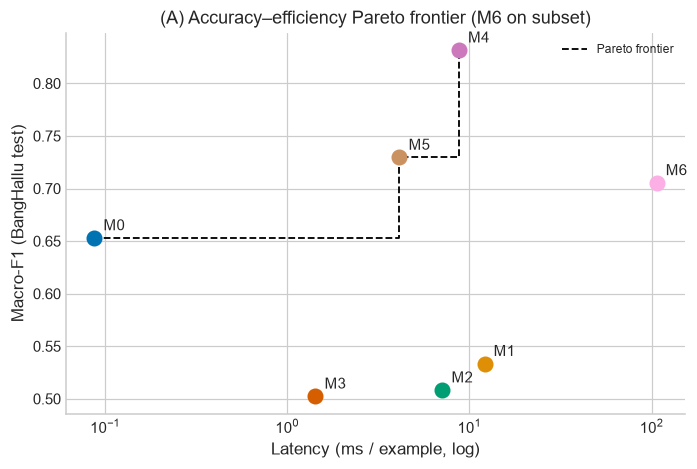

[figure] saved fig6a_pareto_preview.png/.pdf @300dpi


In [31]:
# Stage 5.6 — Table 5 and Fig 6A preview
rows = []
for k, lbl in (("M0", "M0 Lexical"), ("M1", "M1 English LettuceDetect"), ("M2", "M2 released EuroBERT-210M LettuceDetect (Chinese RAGTruth fine-tune)"), ("M2STAR", "M2* EuroBERT-210M fine-tuned on English RAGTruth"), ("M3", "M3 XLM-R-base (100%)"), ("M4", "M4 BanglaBERT-large (100%)")):
    if k in F_RES:
        bh_, ol_ = F_RES[k]["bh"], F_RES[k]["ol"]
        rows.append({"Section": "External generalization (Olikbochon)", "Setting": lbl, "Macro-F1": mean_sd(bh_), "Olikbochon Macro-F1": mean_sd(ol_),
                     "Δ Macro-F1 (Olik − BangHallu)": float(np.mean(ol_) - np.mean(bh_)), "AUROC": mean_sd(F_RES[k]["auroc"])})
for r in POOL_ROWS + QUERY_ROWS:
    rows.append({"Section": r["Section"], "Setting": r["Setting"], "Macro-F1": r["Macro-F1"], "AUROC": r["AUROC"]})
ALL_EFF = {}   # model -> (latency, macro-F1, vram, n)
for k, lst in (("M0", [FROZEN.get("M0")]), ("M1", [FROZEN.get("M1")]),
               ("M2", [FROZEN.get("M2")]), ("M2STAR", [FROZEN.get("M2STAR")])):
    if lst[0]: ALL_EFF[k] = (lst[0]["metrics"]["latency_ms"], lst[0]["metrics"]["macro_f1"], lst[0]["metrics"]["peak_vram_mb"], len(BH_TEST))
for k in ("M3", "M4"):
    L = STAGE4[(k, 1.0)]; ALL_EFF[k] = (np.mean([np.mean([r["latency_ms"] for r in d["test"]]) for d in L]), np.mean([d["metrics"]["macro_f1"] for d in L]), np.nanmean([d["metrics"]["peak_vram_mb"] for d in L]), len(BH_TEST))
if M5_RES: ALL_EFF["M5"] = (np.mean([np.mean([r["latency_ms"] for r in d["test"]]) for d in M5_RES]), np.mean([d["metrics"]["macro_f1"] for d in M5_RES]), np.nanmean([d["metrics"]["peak_vram_mb"] for d in M5_RES]), len(BH_TEST))
if M6_RES: ALL_EFF["M6"] = (np.mean([r["latency_ms"] for r in M6_RES["test"]]), M6_RES["metrics"]["macro_f1"], M6_RES["metrics"]["peak_vram_mb"], M6_RES["n"])
for k, (lat, f1, vr, n) in ALL_EFF.items():
    rows.append({"Section": "Accuracy vs efficiency (RQ6)", "Setting": {"M0": "M0 Lexical", "M1": "M1 English LettuceDetect", "M2": "M2 released EuroBERT-210M LettuceDetect (Chinese RAGTruth fine-tune)", "M2STAR": "M2* EuroBERT-210M fine-tuned on English RAGTruth", "M3": "M3 XLM-R-base", "M4": "M4 BanglaBERT-large",
                 "M5": "M5 MIL token detector", "M6": "M6 3B 4-bit LLM verifier (subset)"}[k], "Macro-F1": f1, "Latency ms/ex": lat, "Peak VRAM MB": vr, "N eval": n})
t5 = pd.DataFrame(rows).fillna("--")
save_table(t5, "table5_external_generalization_and_ablations", "External generalization (frozen weights and thresholds), pooling and query-conditioning ablations, and accuracy-vs-efficiency comparison. M6 is evaluated on a stratified subset.",
           higher_better=["Macro-F1", "AUROC"], lower_better=["Latency ms/ex", "Peak VRAM MB"], group_col="Section")

def pareto_front(pts):
    """pts: list of (latency, f1, name); a point is on the front if no other has lower-or-equal latency and higher-or-equal F1."""
    return [p for p in pts if not any((q[0] <= p[0] and q[1] >= p[1]) and (q[0] < p[0] or q[1] > p[1]) for q in pts)]

def plot_fig6a(ax):
    pts = [(v[0] if v[0] > 0 else 1e-2, v[1], k) for k, v in ALL_EFF.items()]
    for i, (lat, f1, k) in enumerate(pts):
        ax.scatter(lat, f1, s=90, color=PALETTE[i % 10], zorder=3); ax.annotate(k, (lat, f1), textcoords="offset points", xytext=(6, 5), fontsize=10)
    fr = sorted(pareto_front(pts)); ax.step([p[0] for p in fr], [p[1] for p in fr], where="post", color="k", ls="--", lw=1.2, label="Pareto frontier")
    ax.set_xscale("log"); ax.set_xlabel("Latency (ms / example, log)"); ax.set_ylabel("Macro-F1 (BangHallu test)"); ax.set_title("(A) Accuracy–efficiency Pareto frontier (M6 on subset)"); ax.legend(fontsize=8)
fig, ax = plt.subplots(figsize=(6.5, 4.4)); plot_fig6a(ax); fig.tight_layout(); save_fig(fig, "fig6a_pareto_preview")

## Stage 6 — Experiment G: Bangladesh legal domain shift (BanglaGovRAG + BD Legal QA)
Gold-evidence vs retrieved-evidence conditions, language subsets, refusal probe, and a *secondary, explicitly synthetic* perturbation stress test.

In [32]:
# Stage 6.1 — legal frames, language detection
LEGAL_MAX_Q = 2000
ROMAN_BN = {"ki", "kno", "keno", "ache", "nai", "hobe", "kore", "ta", "amar", "apni", "ain", "ainer", "dhara", "jodi", "jonno", "koto", "kivabe", "kothay", "kemon", "ebong", "othoba", "bangladesh", "er", "te", "ke", "naki", "pabo", "korte", "hoy", "hole"}
def detect_lang(q):
    q = str(q); bn = len(BN_RANGE.findall(q)); la = len(LAT_RANGE.findall(q)); tot = max(bn + la, 1)
    if bn / tot > 0.6: return "BN"
    if bn == 0:
        toks = set(re.findall(r"[a-z]+", q.lower()))
        return "CS" if len(toks & ROMAN_BN) >= 2 else "EN"
    return "CS"

def legal_base(key):
    d = DATA.get(key)
    if d is None: return None
    d = d[d["answer"].astype(str).str.len() > 0].copy(); d = d[d["question"].astype(str).str.len() > 0]
    has_ctx = d["context"].astype(str).str.len() > 20
    def first_sent(a):
        ss = [s.strip() for s in re.split(r"(?<=[।.!?])\s+", str(a)) if len(s.strip()) > 10]; return ss[0] if ss else str(a)
    d = d.assign(doc=np.where(has_ctx, d["context"].astype(str), d["answer"].astype(str)),
                 claim=[a if h else first_sent(a) for a, h in zip(d["answer"].astype(str), has_ctx)],
                 evidence_mode=np.where(has_ctx, "provided_context", "answer_as_evidence"))
    return d

LEG_FRAMES = [x for x in (legal_base("banglagovrag"), legal_base("bdlegalqa")) if x is not None]
if not LEG_FRAMES:
    print("[WARN] No legal dataset available -> Stage 6 skipped (Table 6 / Fig 5 not generated)")
else:
    LEG = pd.concat(LEG_FRAMES, ignore_index=True)
    if len(LEG) > LEGAL_MAX_Q:
        LEG = LEG.sample(LEGAL_MAX_Q, random_state=42).reset_index(drop=True)
    LEG["lang"] = LEG["question"].map(detect_lang)
    LEG["doc_id"] = LEG["doc"].map(lambda t: hashlib.md5(re.sub(r"\s+", " ", t.strip()).encode()).hexdigest()[:12])
    LEG["qid"] = [stable_id(a, b, c) for a, b, c in zip(LEG["dataset"], LEG["question"], LEG["id"])]
    print(LEG.groupby(["dataset", "lang"]).size())

dataset       lang
banglagovrag  BN       71
              CS        1
              EN       28
bdlegalqa     BN      900
              EN      607
dtype: int64


In [33]:
# Stage 6.2 — passage corpus + hybrid retriever (BM25 + multilingual-E5, reciprocal-rank fusion)
if LEG_FRAMES:
    from rank_bm25 import BM25Okapi
    import faiss
    from sentence_transformers import SentenceTransformer
    CHUNK_W, STRIDE_W = 120, 100
    # the corpus is built from every document of the *full* legal frames (not only the sampled eval rows) so retrieval is non-trivial
    ALL_LEG = pd.concat(LEG_FRAMES, ignore_index=True)
    DOCS = {}
    for t in ALL_LEG["doc"].tolist():
        DOCS[hashlib.md5(re.sub(r"\s+", " ", t.strip()).encode()).hexdigest()[:12]] = t
    CORPUS = []
    for did, t in DOCS.items():
        w = t.split()
        for s in range(0, max(len(w), 1), STRIDE_W):
            CORPUS.append(dict(cid=len(CORPUS), doc_id=did, text=" ".join(w[s:s + CHUNK_W])))
            if s + CHUNK_W >= len(w): break
    C_TEXT = [c["text"] for c in CORPUS]; C_DOC = np.array([c["doc_id"] for c in CORPUS]); print("corpus:", len(DOCS), "docs,", len(CORPUS), "chunks")
    bm25 = BM25Okapi([_tok_words(t) for t in C_TEXT])
    emb_path = CACHE / f"legal_emb_{hashlib.md5(('|'.join(C_TEXT[:200]) + str(len(C_TEXT))).encode()).hexdigest()[:10]}.npy"
    e5 = SentenceTransformer(E5_MODEL, device=DEVICE)
    if emb_path.exists(): C_EMB = np.load(emb_path)
    else:
        C_EMB = e5.encode(["passage: " + t for t in C_TEXT], batch_size=32, normalize_embeddings=True, show_progress_bar=True).astype("float32"); np.save(emb_path, C_EMB)
    index = faiss.IndexFlatIP(C_EMB.shape[1]); index.add(C_EMB)

    def retrieve(question, k=50, rrf_k=60):
        qv = e5.encode(["query: " + question], normalize_embeddings=True).astype("float32")
        ds, di = index.search(qv, k); di = di[0]
        bs = bm25.get_scores(_tok_words(question)); bi = np.argpartition(-bs, min(k, len(bs) - 1))[:k]; bi = bi[np.argsort(-bs[bi])]
        fused = collections.defaultdict(float)
        for r, c in enumerate(di): fused[int(c)] += 1.0 / (rrf_k + r + 1)
        for r, c in enumerate(bi): fused[int(c)] += 1.0 / (rrf_k + r + 1)
        order = sorted(fused, key=lambda c: -fused[c])
        return [(c, fused[c], float(C_EMB[c] @ qv[0])) for c in order]

    RET = {}
    for _, r in tqdm(LEG.drop_duplicates("qid").iterrows(), total=LEG["qid"].nunique(), desc="retrieval"):
        RET[r["qid"]] = retrieve(str(r["question"]))
    e5 = None; reset_gpu()                      # free the E5 encoder's VRAM before the detectors are loaded
    qdf = LEG.drop_duplicates("qid")[["qid", "dataset", "lang", "doc_id"]].reset_index(drop=True)
    def retr_metrics(sub):
        r1 = r5 = mrr = 0.0
        for _, r in sub.iterrows():
            docs = [C_DOC[c] for c, _, _ in RET[r["qid"]]]
            r1 += docs[0] == r["doc_id"]; r5 += r["doc_id"] in docs[:5]
            rank = next((i + 1 for i, d in enumerate(docs) if d == r["doc_id"]), None); mrr += 1 / rank if rank else 0.0
        n = max(len(sub), 1); return dict(r1=r1 / n, r5=r5 / n, mrr=mrr / n, n=len(sub))
    RETR_ROWS = []
    for lang in ["All", "BN", "CS", "EN"]:
        sub = qdf if lang == "All" else qdf[qdf.lang == lang]
        if len(sub): m = retr_metrics(sub); RETR_ROWS.append({"Section": "Retrieval (BM25 + E5, RRF)", "Model": "Hybrid retriever", "Condition": "Retrieved", "Language": lang, "N": m["n"], "Recall@1": m["r1"], "Recall@5": m["r5"], "MRR": m["mrr"]})
    print(pd.DataFrame(RETR_ROWS))

corpus: 1096 docs, 1219 chunks


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


... (7 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/39 [00:00<?, ?it/s]

retrieval:   0%|          | 0/1607 [00:00<?, ?it/s]

                      Section             Model  Condition Language     N  \
0  Retrieval (BM25 + E5, RRF)  Hybrid retriever  Retrieved      All  1607   
1  Retrieval (BM25 + E5, RRF)  Hybrid retriever  Retrieved       BN   971   
2  Retrieval (BM25 + E5, RRF)  Hybrid retriever  Retrieved       CS     1   
3  Retrieval (BM25 + E5, RRF)  Hybrid retriever  Retrieved       EN   635   

   Recall@1  Recall@5       MRR  
0  0.227754  0.408836  0.318088  
1  0.185376  0.340886  0.266030  
2  1.000000  1.000000  1.000000  
3  0.291339  0.511811  0.396618  


In [34]:
# Stage 6.3 — evidence conditions, evaluation pairs (synthetic negatives flagged), OOC refusal probe
if LEG_FRAMES:
    def gold_evidence(doc, ref, k=3):
        ch = [" ".join(doc.split()[s:s + CHUNK_W]) for s in range(0, max(len(doc.split()), 1), STRIDE_W)]
        aw = set(_tok_words(ref)); sc = [len(aw & set(_tok_words(c))) for c in ch]
        top = sorted(np.argsort(sc)[::-1][:k]); return "\n".join(ch[i] for i in top)
    base = LEG.assign(context="", answer=LEG["claim"], label_answer=np.nan,
                      metadata=[dict(qid=q, lang=l, evidence_mode=e) for q, l, e in zip(LEG["qid"], LEG["lang"], LEG["evidence_mode"])])
    base = base[SCHEMA]
    PAIRS = synthesize_pairs(base)                                                      # label 1 rows are SYNTHETIC perturbations
    PAIRS["qid"] = PAIRS["metadata"].map(lambda m: m["qid"]); PAIRS["lang"] = PAIRS["metadata"].map(lambda m: m["lang"])
    PAIRS["perturb"] = PAIRS["metadata"].map(lambda m: m.get("perturb", "none")); PAIRS["label_source"] = PAIRS["metadata"].map(lambda m: m.get("label_source"))
    claim_by_q = dict(zip(LEG["qid"], LEG["claim"])); doc_by_q = dict(zip(LEG["qid"], LEG["doc"]))
    GOLD_EV = {q: gold_evidence(doc_by_q[q], claim_by_q[q]) for q in doc_by_q}
    RET_EV = {q: "\n".join(C_TEXT[c] for c, _, _ in RET[q][:3]) for q in RET}
    GOLD_DF = PAIRS.assign(context=PAIRS["qid"].map(GOLD_EV)).reset_index(drop=True)
    RET_DF = PAIRS.assign(context=PAIRS["qid"].map(RET_EV)).reset_index(drop=True)
    # out-of-corpus probe: remove the gold document from the ranking -> evidence cannot support the (reference) claim -> label 1 ("unsupported / refuse")
    OOC_EV = {q: "\n".join(C_TEXT[c] for c, _, _ in [x for x in RET[q] if C_DOC[x[0]] != g][:3]) for q, g in zip(qdf["qid"], qdf["doc_id"])}
    OOC_DF = PAIRS[PAIRS["perturb"] == "none"].assign(context=lambda d: d["qid"].map(OOC_EV), label_answer=1, id=lambda d: d["id"] + "_ooc").reset_index(drop=True)
    for nm, d in (("GOLD", GOLD_DF), ("RET", RET_DF), ("OOC", OOC_DF)): print(nm, len(d), "label mean", round(d.label_answer.mean(), 3))

    # retrieval-score refusal probe: refuse if top-1 dense cosine < theta; theta tuned on a hash-split dev half, reported on test half
    ref_rows = []
    for _, r in qdf.iterrows():
        inc = RET[r["qid"]][0][2]; ooc = next((x[2] for x in RET[r["qid"]] if C_DOC[x[0]] != r["doc_id"]), np.nan)
        ref_rows.append(dict(qid=r["qid"], lang=r["lang"], incorpus=inc, ooc=ooc, half="dev" if qhash(r["qid"]) % 2 == 0 else "test"))
    REF = pd.DataFrame(ref_rows).dropna()
    dv = REF[REF.half == "dev"]; cand = np.unique(np.quantile(np.concatenate([dv.incorpus, dv.ooc]), np.linspace(0.02, 0.98, 97)))
    theta = max(cand, key=lambda t: 0.5 * ((dv.incorpus >= t).mean() + (dv.ooc < t).mean()))
    ts = REF[REF.half == "test"]
    REFUSAL = dict(theta=float(theta), acc_ooc_refuse=float((ts.ooc < theta).mean()), acc_incorpus_answer=float((ts.incorpus >= theta).mean()))
    REFUSAL["balanced"] = 0.5 * (REFUSAL["acc_ooc_refuse"] + REFUSAL["acc_incorpus_answer"]); print("Refusal probe (retrieval-score):", REFUSAL)

GOLD 1364 label mean 0.5
RET 1364 label mean 0.5
OOC 682 label mean 1.0
Refusal probe (retrieval-score): {'theta': 0.8436293184757233, 'acc_ooc_refuse': 0.8320987654320988, 'acc_incorpus_answer': 0.2679012345679012, 'balanced': 0.55}


In [35]:
# Stage 6.4 — run detectors on Gold / Retrieved / OOC conditions
if LEG_FRAMES:
    LEG_MODELS = [("M0", "M0", [0], lambda s: (lambda: LexicalScorer())),
                  ("M1", "M1", [0], lambda s: (lambda: HFScorer(M1_PATH, "token", 4096, False, True))),
                  ("M2", "M2", [0], lambda s: (lambda: HFScorer(ensure_m2_path(), "token", 4096, False, True)))] + \
                 [(m, mkey(m, 1.0), SEEDS, (lambda s, m=m: (lambda: seq_scorer(m, ensure_ckpt(m, 1.0, s))))) for m in ("M3", "M4")]
    if RUN_M2STAR_SUPPLEMENTARY and M2STAR_PATH is not None:
        LEG_MODELS.insert(3, ("M2STAR", "M2STAR", [0], lambda s: (lambda: HFScorer(M2STAR_PATH, "token", 4096, False, True))))
    LEG_RES = {}   # (model, cond) -> {seed: recs}
    for label, key, seeds, mk_factory in LEG_MODELS:
        if label == "M1" and M1_PATH is None: continue
        if label == "M2" and M2_PATH is None and rag is None: continue
        for seed in seeds:
            need = [pred_path(f"G_{c}", key, seed).exists() for c in ("gold", "ret", "ooc")]
            if all(need):
                lz = Lazy(lambda: None)
            else:
                lz = Lazy(mk_factory(seed), key=f"{key}_legal")
            with lz:
                tau = THRESHOLDS.get(tau_key(key, seed), 0.5)
                for cond, df in (("gold", GOLD_DF), ("ret", RET_DF), ("ooc", OOC_DF)):
                    LEG_RES.setdefault((label, cond), {})[seed] = cached_predict(f"G_{cond}", key, seed, df, lz, tau)
            print(label, "seed", seed, "done")

M0 seed 0 done
M1 seed 0 done
M2 seed 0 done


The tokenizer you are loading from 'checkpoints\M3-100pct_seed42' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


M3 seed 42 done


The tokenizer you are loading from 'checkpoints\M3-100pct_seed1337' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


M3 seed 1337 done


The tokenizer you are loading from 'checkpoints\M3-100pct_seed2026' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


M3 seed 2026 done
M4 seed 42 done
M4 seed 1337 done
M4 seed 2026 done


[table] saved table6_legal_domain_shift.csv/.tex (70 rows)


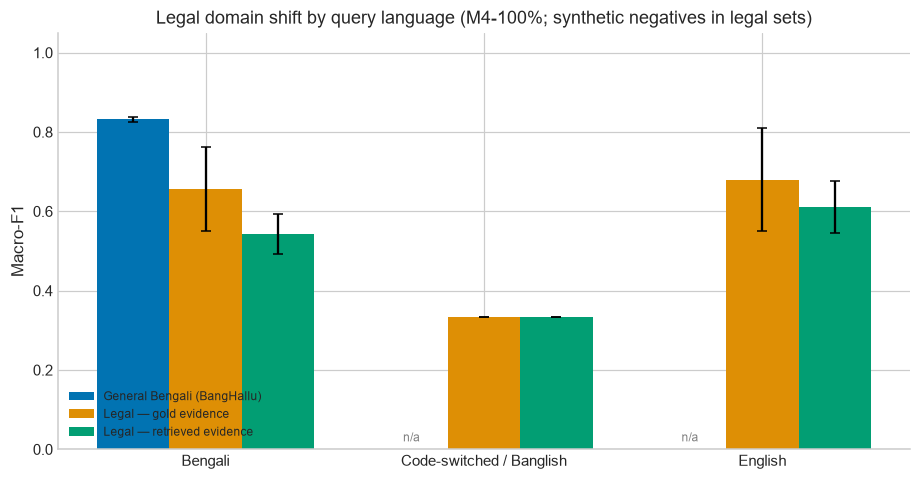

[figure] saved fig5_legal_domain_shift_analysis.png/.pdf @300dpi


In [36]:
# Stage 6.5 — Table 6 and Fig 5
def subset_eval(recs, df, mask):
    y = np.array([r["gold_label"] for r in recs])[mask]; p = np.array([r["pred_prob"] for r in recs])[mask]; pl = np.array([r["pred_label"] for r in recs])[mask]
    if len(y) == 0: return None
    return dict(f1=macro_f1(y, pl) if len(np.unique(y)) > 1 else float("nan"), rec=float(((pl == 1) & (y == 1)).sum() / max((y == 1).sum(), 1)),
                fpr=float(((pl == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)), auroc=safe_auc(y, p), n=int(len(y)))

if LEG_FRAMES:
    rows = list(RETR_ROWS); DET = {}
    for (label, cond), by_seed in LEG_RES.items():
        df = {"gold": GOLD_DF, "ret": RET_DF, "ooc": OOC_DF}[cond]
        langs = df["lang"].values
        if cond == "ooc":
            vals = [subset_eval(r, df, np.ones(len(df), bool)) for r in by_seed.values()]
            rows.append({"Section": "Out-of-corpus refusal probe", "Model": label, "Condition": "OOC evidence", "Language": "All", "N": vals[0]["n"], "Refusal acc (detector flags unsupported)": mean_sd([v["rec"] for v in vals])}); continue
        for lang in ["All", "BN", "CS", "EN"]:
            mask = np.ones(len(df), bool) if lang == "All" else (langs == lang)
            vals = [v for v in (subset_eval(r, df, mask) for r in by_seed.values()) if v]
            if not vals: continue
            DET[(label, cond, lang)] = vals
            rows.append({"Section": "Detection (labels: reference=0 / synthetic perturbation=1)", "Model": label, "Condition": "Gold evidence" if cond == "gold" else "Retrieved evidence",
                         "Language": lang, "N": vals[0]["n"], "Macro-F1": mean_sd([v["f1"] for v in vals]), "Hallucination recall": mean_sd([v["rec"] for v in vals]),
                         "False-alarm rate": mean_sd([v["fpr"] for v in vals]), "AUROC": mean_sd([v["auroc"] for v in vals])})
    rows.append({"Section": "Out-of-corpus refusal probe", "Model": "Retriever score threshold", "Condition": f"theta={REFUSAL['theta']:.3f}", "Language": "All", "N": len(ts),
                 "Refusal acc (detector flags unsupported)": f"OOC refuse {REFUSAL['acc_ooc_refuse']:.3f} / in-corpus answer {REFUSAL['acc_incorpus_answer']:.3f} / balanced {REFUSAL['balanced']:.3f}"})
    # secondary SYNTHETIC stress test: recall per perturbation type, gold-evidence condition
    ptypes = sorted(set(GOLD_DF.loc[GOLD_DF.perturb != "none", "perturb"]))
    for label in [m[0] for m in LEG_MODELS if (m[0], "gold") in LEG_RES]:
        for pt in ptypes:
            mask = (GOLD_DF["perturb"] == pt).values
            vals = []
            for recs in LEG_RES[(label, "gold")].values():
                pl = np.array([r["pred_label"] for r in recs])[mask]; vals.append(float((pl == 1).mean()))
            rows.append({"Section": "Synthetic perturbation stress test (SYNTHETIC)", "Model": label, "Condition": "Gold evidence", "Language": "All", "N": int(mask.sum()), "Perturbation": pt, "Hallucination recall": mean_sd(vals)})
    t6 = pd.DataFrame(rows).fillna("--")
    save_table(t6, "table6_legal_domain_shift", "Legal domain shift (BanglaGovRAG + BD Legal QA). Gold-evidence vs retrieved-evidence (BM25 + multilingual E5, RRF), language subsets, refusal probe, and a secondary synthetic perturbation stress test. Negatives are synthetic perturbations of reference answers unless a dataset provides native labels.",
               higher_better=["Macro-F1", "Hallucination recall", "AUROC", "Recall@1", "Recall@5", "MRR"], lower_better=["False-alarm rate"], group_col="Section")

    # Figure 5: General vs Legal-gold vs Legal-retrieved, per language subset (best adapted model)
    best_label = BEST_ADAPTED; langs3 = ["BN", "CS", "EN"]
    bh_lang = BH_TEST["question"].map(detect_lang).values
    gen = {l: [] for l in langs3}
    for d in STAGE4[(best_label, 1.0)]:
        pl = np.array([int(r["pred_prob"] >= d["tau"]) for r in d["test"]]); yy = np.array([r["gold_label"] for r in d["test"]])
        for l in langs3:
            if (bh_lang == l).sum() > 5 and len(np.unique(yy[bh_lang == l])) > 1: gen[l].append(macro_f1(yy[bh_lang == l], pl[bh_lang == l]))
    fig, ax = plt.subplots(figsize=(8.5, 4.5)); w = 0.26; x = np.arange(3)
    series = [("General Bengali (BangHallu)", [(np.mean(gen[l]) if gen[l] else np.nan, np.std(gen[l]) if len(gen[l]) > 1 else 0) for l in langs3]),
              ("Legal — gold evidence", [(np.mean([v["f1"] for v in DET[(best_label, "gold", l)]]), np.std([v["f1"] for v in DET[(best_label, "gold", l)]])) if (best_label, "gold", l) in DET else (np.nan, 0) for l in langs3]),
              ("Legal — retrieved evidence", [(np.mean([v["f1"] for v in DET[(best_label, "ret", l)]]), np.std([v["f1"] for v in DET[(best_label, "ret", l)]])) if (best_label, "ret", l) in DET else (np.nan, 0) for l in langs3])]
    for i, (nm, vals) in enumerate(series):
        ax.bar(x + (i - 1) * w, [v[0] for v in vals], w, yerr=[v[1] for v in vals], capsize=3, label=nm, color=PALETTE[i])
        for xi, v in zip(x + (i - 1) * w, vals):
            if np.isnan(v[0]): ax.text(xi, 0.02, "n/a", ha="center", fontsize=8, color="gray")
    ax.set_xticks(x); ax.set_xticklabels(["Bengali", "Code-switched / Banglish", "English"]); ax.set_ylim(0, 1.05); ax.set_ylabel("Macro-F1")
    ax.set_title(f"Legal domain shift by query language ({best_label}-100%; synthetic negatives in legal sets)"); ax.legend(fontsize=8, loc="lower left")
    fig.tight_layout(); save_fig(fig, "fig5_legal_domain_shift_analysis")

## Stage 7 — Statistical rigor, calibration and selective prediction

In [37]:
# Stage 7.1 — seed-ensembled predictions per model (BangHallu test)
from scipy import stats as sps
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

def collect_test(model_label):
    """Return y, mean P(hallucinated) across seeds, mean tau, per-seed hard predictions, majority-vote prediction."""
    if model_label in ("M0", "M1", "M2", "M2STAR"):
        v = FROZEN[model_label]; lst = [dict(test=v["test"], tau=v["tau"])]
    elif model_label == "M5":
        lst = M5_RES
    else:
        m, frac = model_label.split("-"); lst = STAGE4[(m, int(frac.replace("pct", "")) / 100 if frac != "0pct" else 0.0)]
    y = np.array([r["gold_label"] for r in lst[0]["test"]]); P = np.stack([[r["pred_prob"] for r in d["test"]] for d in lst])
    hard = np.stack([(P[i] >= lst[i]["tau"]).astype(int) for i in range(len(lst))])
    vote = (hard.mean(0) >= 0.5).astype(int)
    return dict(y=y, p=P.mean(0), tau=float(np.mean([d["tau"] for d in lst])), hard=hard, vote=vote, ids=[r["id"] for r in lst[0]["test"]])

STATS_CANDIDATES = ["M1", "M2", "M3-100pct", "M4-100pct", "M4-10pct"]
if RUN_M2STAR_SUPPLEMENTARY and "M2STAR" in FROZEN:
    STATS_CANDIDATES.insert(2, "M2STAR")
STATS_MODELS = {k: collect_test(k) for k in STATS_CANDIDATES if (k in FROZEN or "pct" in k)}

def paired_boot_delta(y, a, b, B=N_BOOT, seed=0):
    idx = boot_indices(len(y), B, seed); fa, fb = _macro_f1_batch(y[idx], a[idx]), _macro_f1_batch(y[idx], b[idx]); d = fa - fb
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

def cohens_h(acc_a, acc_b): return float(2 * math.asin(math.sqrt(acc_a)) - 2 * math.asin(math.sqrt(acc_b)))

def pairwise(a_key, b_key):
    A, B = STATS_MODELS[a_key], STATS_MODELS[b_key]; assert A["ids"] == B["ids"], "test sets must align"
    y, pa, pb = A["y"], A["vote"], B["vote"]
    d = macro_f1(y, pa) - macro_f1(y, pb); lo, hi = paired_boot_delta(y, pa, pb)
    ca, cb = (pa == y), (pb == y); b01 = int((ca & ~cb).sum()); c10 = int((~ca & cb).sum())
    if b01 + c10 == 0: chi, p = 0.0, 1.0
    else:
        r = mcnemar([[int((ca & cb).sum()), b01], [c10, int((~ca & ~cb).sum())]], exact=False, correction=True); chi, p = float(r.statistic), float(r.pvalue)
    return dict(delta=d, lo=lo, hi=hi, chi2=chi, p=p, h=cohens_h(ca.mean(), cb.mean()))

COMPARISONS = [("M2", "M1", "M2-CN vs M1-EN"), ("M4-100pct", "M2", "M4-100% vs M2-CN"),
               ("M4-100pct", "M3-100pct", "M4-100% vs M3-100%"), ("M4-10pct", "M4-100pct", "M4-10% vs M4-100%")]
if RUN_M2STAR_SUPPLEMENTARY and "M2STAR" in STATS_MODELS:
    COMPARISONS.extend([("M2STAR", "M1", "M2*-EN-finetuned vs M1-EN-released"), ("M2STAR", "M2", "M2*-EN-finetuned vs M2-CN-released")])
rows = []
for a, b, lbl in COMPARISONS:
    if a in STATS_MODELS and b in STATS_MODELS: rows.append((lbl, pairwise(a, b)))
if rows:
    padj = multipletests([r["p"] for _, r in rows], alpha=0.05, method="holm")[1]
    t7 = pd.DataFrame([{"Comparison": lbl, "Δ Macro-F1": r["delta"], "95% paired bootstrap CI of Δ": f"[{r['lo']:.3f}, {r['hi']:.3f}]", "McNemar χ²": r["chi2"],
                        "p (raw)": r["p"], "p (Holm-Bonferroni)": float(pa), "Cohen's h": r["h"], "Significant (Holm α=0.05)": "yes" if pa < 0.05 else "no"} for (lbl, r), pa in zip(rows, padj)])
    save_table(t7, "table7_statistical_significance_matrix", "Pairwise significance on BangHallu test (seed-majority-vote predictions): paired bootstrap CI of Δ Macro-F1 (1000 resamples), McNemar's test with continuity correction, Holm-Bonferroni adjustment over the family, Cohen's h on accuracy.",
               lower_better=["p (Holm-Bonferroni)"])

[table] saved table7_statistical_significance_matrix.csv/.tex (4 rows)


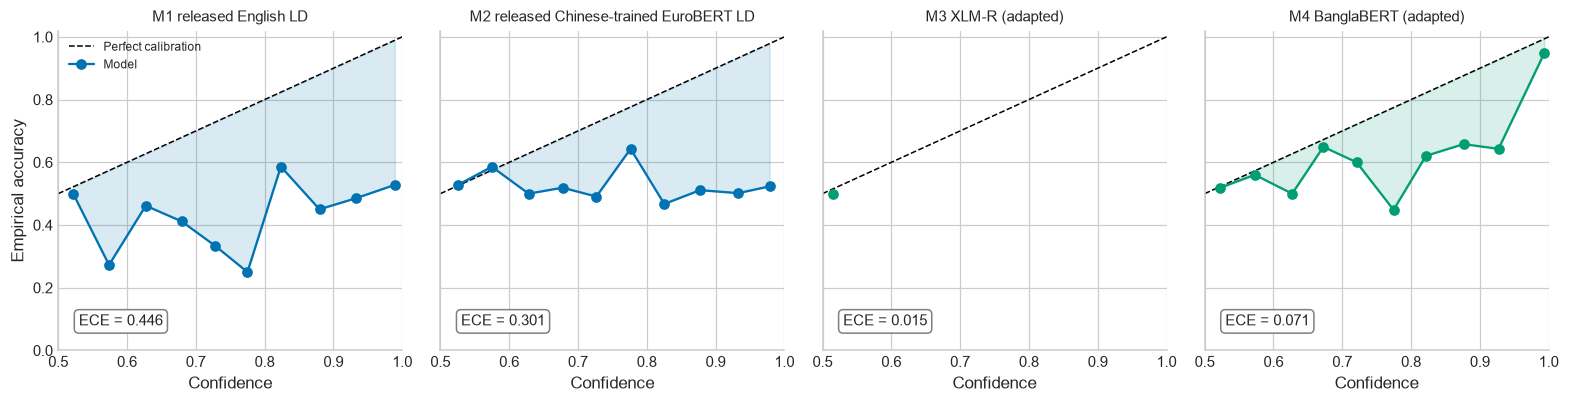

[figure] saved fig3_calibration_reliability_diagrams.png/.pdf @300dpi


In [38]:
# Stage 7.2 — reliability diagrams (Fig 3)
def reliability(y, p, n_bins=10):
    pred = (p >= 0.5).astype(int); conf = np.maximum(p, 1 - p); acc = (pred == y).astype(float); edges = np.linspace(0.5, 1.0, n_bins + 1)
    xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf <= hi) if lo == 0.5 else (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean()); ys.append(acc[m].mean()); ns.append(int(m.sum()))
    return np.array(xs), np.array(ys), np.array(ns)

CAL_MODELS = [("M1", "M1 released English LD", "M1"), ("M2", "M2 released Chinese-trained EuroBERT LD", "M2"),
              ("M3-100pct", "M3 XLM-R (adapted)", "M3-100pct"), ("M4-100pct", "M4 BanglaBERT (adapted)", "M4-100pct")]
if RUN_M2STAR_SUPPLEMENTARY and "M2STAR" in STATS_MODELS:
    CAL_MODELS.insert(2, ("M2STAR", "M2* English-RAGTruth fine-tune", "M2STAR"))
CAL_MODELS = [c for c in CAL_MODELS if c[0] in STATS_MODELS]
fig, axes = plt.subplots(1, len(CAL_MODELS), figsize=(3.6 * len(CAL_MODELS), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, (k, title, _) in zip(axes, CAL_MODELS):
    S = STATS_MODELS[k]; xs, ys, ns = reliability(S["y"], S["p"]); e = ece_score(S["y"], S["p"])
    col = PALETTE[0] if k in ("M1", "M2") else PALETTE[1] if k == "M2STAR" else PALETTE[2]
    ax.plot([0.5, 1], [0.5, 1], "k--", lw=1, label="Perfect calibration"); ax.plot(xs, ys, "o-", color=col, label="Model")
    ax.fill_between(xs, xs, ys, color=col, alpha=0.15); ax.set_xlim(0.5, 1); ax.set_ylim(0, 1.02); ax.set_xlabel("Confidence"); ax.set_title(title, fontsize=10)
    ax.text(0.53, 0.08, f"ECE = {e:.3f}", fontsize=10, bbox=dict(boxstyle="round", fc="white", ec="gray"))
axes[0].set_ylabel("Empirical accuracy"); axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig3_calibration_reliability_diagrams")

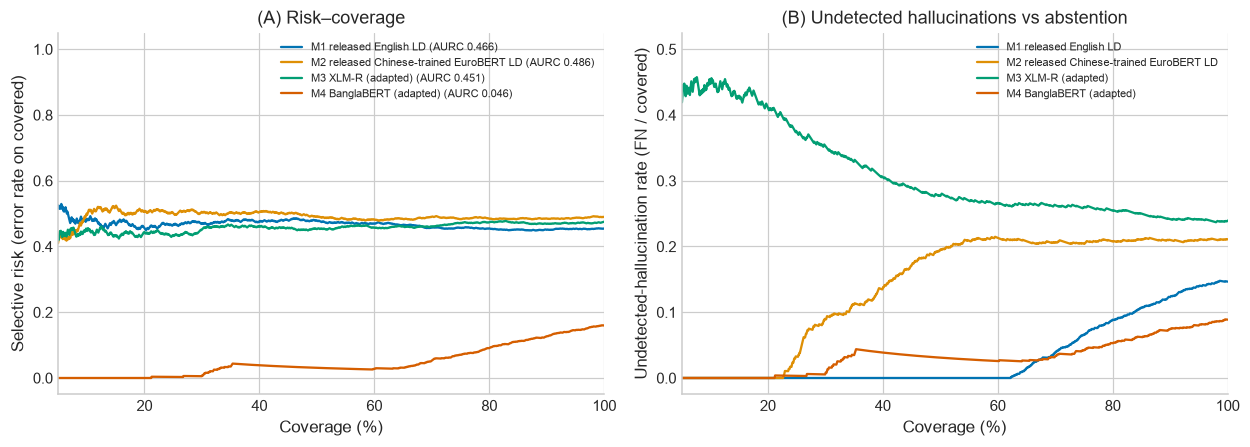

[figure] saved fig4_risk_coverage_curves.png/.pdf @300dpi


In [39]:
# Stage 7.3 — risk–coverage curves (Fig 4)
_trapz = getattr(np, "trapezoid", None) or np.trapz
def risk_coverage(y, p, tau):
    conf = np.abs(p - tau); order = np.argsort(-conf); pred = (p >= tau).astype(int)
    err = (pred != y)[order].astype(float); fn = ((pred == 0) & (y == 1))[order].astype(float); k = np.arange(1, len(y) + 1)
    return k / len(y), np.cumsum(err) / k, np.cumsum(fn) / k
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2)); AURC = {}
for i, (k, title, _) in enumerate(CAL_MODELS):
    S = STATS_MODELS[k]; cov, risk, und = risk_coverage(S["y"], S["p"], S["tau"]); AURC[k] = float(_trapz(risk, cov))
    axes[0].plot(cov * 100, risk, color=PALETTE[i], label=f"{title} (AURC {AURC[k]:.3f})"); axes[1].plot(cov * 100, und, color=PALETTE[i], label=title)
axes[0].set_xlabel("Coverage (%)"); axes[0].set_ylabel("Selective risk (error rate on covered)"); axes[0].set_title("(A) Risk–coverage"); axes[0].legend(fontsize=7)
axes[1].set_xlabel("Coverage (%)"); axes[1].set_ylabel("Undetected-hallucination rate (FN / covered)"); axes[1].set_title("(B) Undetected hallucinations vs abstention"); axes[1].legend(fontsize=7)
for ax in axes: ax.set_xlim(5, 100)
fig.tight_layout(); save_fig(fig, "fig4_risk_coverage_curves")
json.dump(AURC, open(RES / "aurc.json", "w"), indent=1)

## Stage 8 — Stratified error analysis (10 categories, 5 macro-buckets)

In [40]:
# Stage 8.1 — heuristic error taggers
ERR_CATS = {1: "Numeric / date / quantity mismatch", 2: "Entity / term substitution", 3: "Negation / polarity flip", 4: "Unsupported addition (extrinsic)",
            5: "Subtle intrinsic contradiction", 6: "Paraphrase / lexical divergence", 7: "Context truncation loss", 8: "Code-switch / script mismatch",
            9: "Numeral / Unicode normalisation variant", 10: "Legal reference mismatch"}
BUCKETS = {1: "Factual detail", 2: "Factual detail", 10: "Factual detail", 3: "Logical", 5: "Logical", 4: "Extrinsic content", 6: "Surface / form", 8: "Surface / form", 9: "Surface / form", 7: "Input processing"}
NEG_W = {"না", "নয়", "নেই", "নহে", "নি", "not", "no", "never", "cannot", "dont", "doesnt", "isnt"}
LEGAL_RX = re.compile(r"ধারা|অনুচ্ছেদ|আইন|অধ্যাদেশ|বিধি|section|article|\bact\b|ordinance", re.I)
ENC512 = Encoder(load_tokenizer(MODELS["XLM-R-base"]), 512, use_query=True)

def _nums(t): return set(re.findall(r"\d+", unicodedata.normalize("NFKC", str(t)).translate(BN_DIGITS)))
def _latin_ratio(t):
    bn, la = len(BN_RANGE.findall(t)), len(LAT_RANGE.findall(t)); return la / max(bn + la, 1)
def _best_ctx_sentence(ans, ctx):
    aw = set(_tok_words(ans)); ss = [s for s in re.split(r"(?<=[।.!?])\s+|\n", ctx) if s.strip()]
    return max(ss, key=lambda s: len(aw & set(_tok_words(s))), default="")

def tag_error(q, ctx, ans, gold, pred):
    """Deterministic rule-based tagger. Returns category id 1..10 for an error (gold != pred)."""
    e = ENC512.encode(q, ctx, ans); cw = set(_tok_words(ctx)); aw = _tok_words(ans)
    miss = [w for w in aw if w not in cw and len(w) > 1]; r = len(miss) / max(len(aw), 1)
    num_mis = _nums(ans) - _nums(ctx); bn_dig_a, bn_dig_c = bool(re.search("[০-৯]", ans)), bool(re.search("[০-৯]", ctx))
    digit_variant = bool(re.search(r"\d", ans)) and bool(re.search(r"\d", ctx)) and bn_dig_a != bn_dig_c
    neg_diff = (sum(w in NEG_W for w in _tok_words(ans)) % 2) != (sum(w in NEG_W for w in _tok_words(_best_ctx_sentence(ans, ctx))) % 2)
    script_mm = abs(_latin_ratio(ans) - _latin_ratio(ctx)) > 0.5
    tail = ctx[e["ctx_kept_chars"]:] if e["ctx_truncated"] else ""
    tail_hit = bool(tail) and any(w in set(_tok_words(tail)) for w in miss)
    legal = bool(LEGAL_RX.search(ans))
    if gold == 1 and pred == 0:      # missed hallucination (false negative)
        if legal and (num_mis or miss): return 10
        if num_mis: return 1
        if neg_diff: return 3
        if 0 < len(miss) <= 2: return 2
        if r >= 0.3: return 4
        if script_mm: return 8
        return 5
    if digit_variant: return 9       # false alarm on faithful answer
    if script_mm: return 8
    if tail_hit: return 7
    if num_mis: return 1
    if legal and miss: return 10
    return 6

In [41]:
# Stage 8.2 — collect errors across models/datasets, tag, tabulate (Table 8)
ERR_ROWS = []
def add_errors(dataset, df, model, recs):
    for (_, r), rec in zip(df.iterrows(), recs):
        g, p = int(rec["gold_label"]), int(rec["pred_label"])
        if g == p or g < 0: continue
        c = tag_error(str(r["question"]), str(r["context"]), str(r["answer"]), g, p)
        ERR_ROWS.append(dict(dataset=dataset, model=model, id=str(r["id"]), question=r["question"], context=str(r["context"]), answer=r["answer"], gold_label=g, pred_label=p,
                             pred_prob=rec["pred_prob"], error_type="FN" if g == 1 else "FP", category=c, category_name=ERR_CATS[c], macro_bucket=BUCKETS[c]))
for mk in ("M0", "M1", "M2", "M2STAR"):
    if mk in FROZEN: add_errors("BangHallu-test", BH_TEST, "M2*" if mk == "M2STAR" else mk, FROZEN[mk]["test"])
for mn in ("M3", "M4"): add_errors("BangHallu-test", BH_TEST, f"{mn}-100%", STAGE4[(mn, 1.0)][0]["test"])
if M5_RES: add_errors("BangHallu-test", BH_TEST, "M5", M5_RES[0]["test"])
if OLIK is not None:
    for mk in F_RES:
        recs = next(iter(F_RES[mk]["recs"].values())); add_errors("Olikbochon", OLIK, ("M2*" if mk == "M2STAR" else mk) if mk in ("M0", "M1", "M2", "M2STAR") else f"{mk}-100%", recs)
if LEG_FRAMES:
    for (label, cond), by_seed in LEG_RES.items():
        if cond == "gold": add_errors("Legal-gold(synthetic neg.)", GOLD_DF, ("M2*" if label == "M2STAR" else label) if label in ("M0", "M1", "M2", "M2STAR") else f"{label}-100%", next(iter(by_seed.values())))
ERR = pd.DataFrame(ERR_ROWS)
print("total tagged errors:", len(ERR))
model_order = [m for m in ["M0", "M1", "M2", "M2*", "M3-100%", "M4-100%", "M5"] if m in set(ERR.model)] if len(ERR) else []
rows = []
for c in range(1, 11):
    row = {"Category": f"{c}. {ERR_CATS[c]}", "Macro-bucket": BUCKETS[c]}
    for m in model_order:
        sub = ERR[ERR.model == m]; n = int((sub.category == c).sum()); row[m] = f"{n} ({100 * n / max(len(sub), 1):.1f}%)"
    rows.append(row)
rows.append({"Category": "Total errors", "Macro-bucket": "", **{m: str(int((ERR.model == m).sum())) for m in model_order}})
for b in ["Factual detail", "Logical", "Extrinsic content", "Surface / form", "Input processing"]:
    rows.append({"Category": f"Bucket: {b}", "Macro-bucket": b, **{m: f"{100 * ((ERR.model == m) & (ERR.macro_bucket == b)).sum() / max((ERR.model == m).sum(), 1):.1f}%" for m in model_order}})
t8 = pd.DataFrame(rows)
save_table(t8, "table8_error_taxonomy_breakdown", "Automatic error taxonomy (rule-based taggers, BangHallu test + Olikbochon + synthetic-negative legal gold set). Cells: count (share of the model's errors). Manual validation sample: results/error_analysis_100_samples.csv.")

Token indices sequence length is longer than the specified maximum sequence length for this model (1007 > 512). Running this sequence through the model will result in indexing errors


total tagged errors: 6439
[table] saved table8_error_taxonomy_breakdown.csv/.tex (16 rows)


,Category,Macro-bucket,M0,M1,M2,M3-100%,M4-100%,M5
0,1. Numeric / date / quantity mismatch,Factual detail,100 (8.7%),163 (11.7%),179 (13.6%),189 (13.7%),80 (9.0%),88 (27.1%)
1,2. Entity / term substitution,Factual detail,2 (0.2%),93 (6.7%),394 (30.0%),359 (26.1%),102 (11.5%),49 (15.1%)
2,3. Negation / polarity flip,Logical,23 (2.0%),6 (0.4%),77 (5.9%),77 (5.6%),20 (2.3%),0 (0.0%)
3,4. Unsupported addition (extrinsic),Extrinsic content,0 (0.0%),2 (0.1%),34 (2.6%),38 (2.8%),30 (3.4%),15 (4.6%)
4,5. Subtle intrinsic contradiction,Logical,137 (11.9%),94 (6.8%),134 (10.2%),154 (11.2%),46 (5.2%),41 (12.6%)
5,6. Paraphrase / lexical divergence,Surface / form,638 (55.5%),788 (56.7%),439 (33.4%),338 (24.6%),389 (44.0%),126 (38.8%)
6,7. Context truncation loss,Input processing,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
7,8. Code-switch / script mismatch,Surface / form,239 (20.8%),236 (17.0%),17 (1.3%),175 (12.7%),203 (23.0%),2 (0.6%)
8,9. Numeral / Unicode normalisation variant,Surface / form,1 (0.1%),1 (0.1%),1 (0.1%),0 (0.0%),1 (0.1%),1 (0.3%)
9,10. Legal reference mismatch,Factual detail,10 (0.9%),6 (0.4%),40 (3.0%),46 (3.3%),13 (1.5%),3 (0.9%)


In [42]:
# Stage 8.3 — stratified 100-sample sheet for manual annotation
def stratified_sample(err, n=100, seed=42):
    pool = err[err.model.isin(["M2", "M2*", "M4-100%"])].copy()
    if pool.empty: pool = err.copy()
    agg = pool.groupby(["dataset", "id"]).agg(models_wrong=("model", lambda s: ",".join(sorted(set(s)))), prob=("pred_prob", "mean")).reset_index()
    pool = pool.drop_duplicates(["dataset", "id"]).merge(agg, on=["dataset", "id"]); pool["disagree"] = ~pool["models_wrong"].str.contains(",")
    rng = np.random.default_rng(seed); tot = len(pool); take = []
    quota = {c: min(int((pool.category == c).sum()), max(3, int(round(n * (pool.category == c).sum() / max(tot, 1))))) for c in range(1, 11)}
    for c in range(1, 11):
        g = pool[pool.category == c]
        if g.empty: continue
        g = g.assign(_r=rng.random(len(g))).sort_values(["disagree", "_r"], ascending=[False, True]); take.append(g.head(quota[c]))
    s = pd.concat(take) if take else pool.head(0)
    if len(s) > n:                                    # trim from the largest categories
        while len(s) > n:
            big = s.category.value_counts().idxmax(); s = s.drop(s[s.category == big].index[-1])
    elif len(s) < n:
        rest = pool.drop(s.index, errors="ignore"); s = pd.concat([s, rest.sample(min(n - len(s), len(rest)), random_state=seed)])
    return s.sample(frac=1, random_state=seed).reset_index(drop=True)

if len(ERR):
    S = stratified_sample(ERR)
    sheet = pd.DataFrame({"sample_id": range(1, len(S) + 1), "dataset": S["dataset"], "id": S["id"], "models_wrong": S["models_wrong"], "error_type": S["error_type"],
                          "auto_category": S["category"], "auto_category_name": S["category_name"], "macro_bucket": S["macro_bucket"], "question": S["question"],
                          "context_first_600_chars": S["context"].str[:600], "answer": S["answer"], "gold_label": S["gold_label"], "mean_pred_prob": S["prob"].round(4),
                          "manual_category": "", "manual_agrees_with_auto(Y/N)": "", "manual_notes": ""})
    sheet.to_csv(RES / "error_analysis_100_samples.csv", index=False, encoding="utf-8-sig"); print("exported", len(sheet), "rows -> results/error_analysis_100_samples.csv")
    print(sheet.auto_category_name.value_counts())

exported 100 rows -> results/error_analysis_100_samples.csv
auto_category_name
Paraphrase / lexical divergence            35
Entity / term substitution                 24
Numeric / date / quantity mismatch         11
Code-switch / script mismatch              11
Subtle intrinsic contradiction              8
Negation / polarity flip                    4
Unsupported addition (extrinsic)            3
Legal reference mismatch                    3
Numeral / Unicode normalisation variant     1
Name: count, dtype: int64


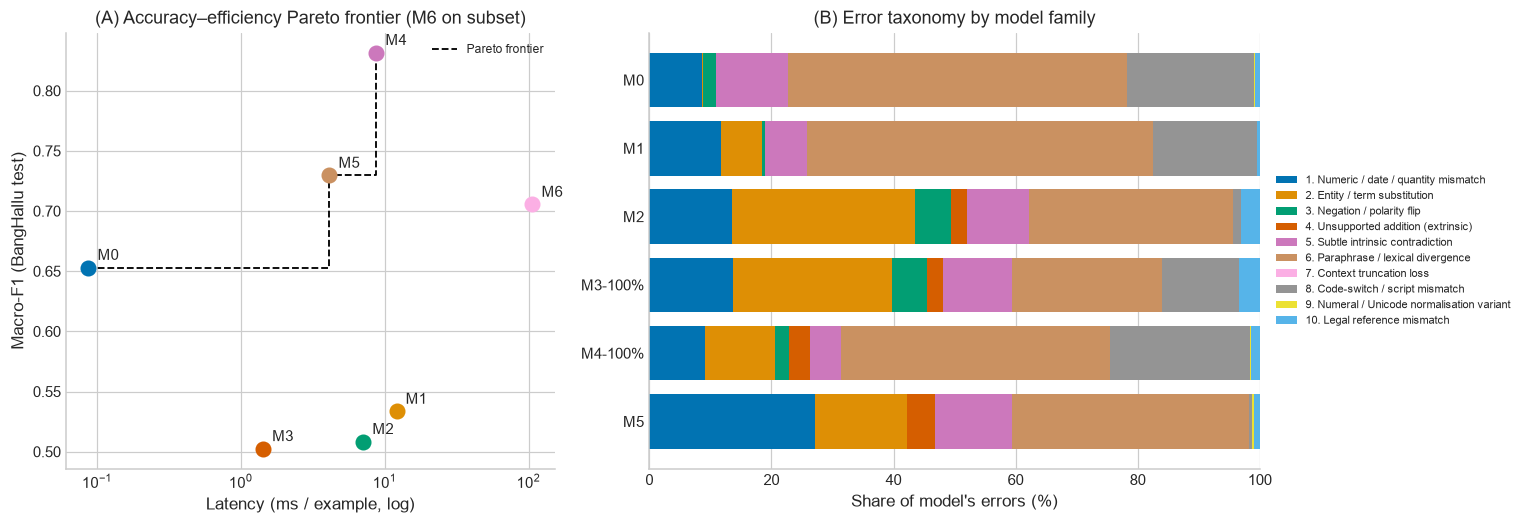

[figure] saved fig6_pareto_efficiency_and_error_taxonomy.png/.pdf @300dpi


In [43]:
# Stage 8.4 — Figure 6 (A: Pareto frontier, B: error taxonomy)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1, 1.25]})
plot_fig6a(axes[0]); ax = axes[1]
if len(ERR):
    share = np.array([[100 * ((ERR.model == m) & (ERR.category == c)).sum() / max((ERR.model == m).sum(), 1) for c in range(1, 11)] for m in model_order])
    left = np.zeros(len(model_order)); cols = sns.color_palette("colorblind", 10)
    for c in range(10):
        ax.barh(model_order, share[:, c], left=left, color=cols[c], label=f"{c + 1}. {ERR_CATS[c + 1]}"); left += share[:, c]
    ax.invert_yaxis(); ax.set_xlabel("Share of model's errors (%)"); ax.set_title("(B) Error taxonomy by model family"); ax.set_xlim(0, 100)
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(); save_fig(fig, "fig6_pareto_efficiency_and_error_taxonomy")

## Stage 9 — Reproducibility manifest and paper-ready summary

In [44]:
# Stage 9.1 — experiment manifest
import datetime, importlib.metadata as md
def _ver(p):
    try: return md.version(p)
    except Exception: return "n/a"
manifest = dict(
    created_utc=datetime.datetime.utcnow().isoformat() + "Z", notebook="ProofBangla_Master_Experiments.ipynb",
    environment=dict(python=sys.version, platform=platform.platform(), torch=torch.__version__, cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
                     vram_gb=round(VRAM_GB, 2), amp_dtype=str(AMP_DTYPE), packages={p: _ver(p) for p in ["transformers", "datasets", "scikit-learn", "scipy", "statsmodels", "rank_bm25", "sentence-transformers", "faiss-cpu", "lettucedetect", "bitsandbytes", "numpy", "pandas", "matplotlib", "seaborn"]}),
    config=dict(seeds=SEEDS, fast_single_seed=FAST_SINGLE_SEED, fractions=FRACTIONS, n_bootstrap=N_BOOT, llm_eval_n=LLM_EVAL_N, train_bs=TRAIN_BS, effective_bs=EFFECTIVE_BS, infer_bs=INFER_BS, grad_ckpt=GRAD_CKPT,
                require_released_m1=REQUIRE_RELEASED_M1, require_released_m2=REQUIRE_RELEASED_M2, run_m2star_supplementary=RUN_M2STAR_SUPPLEMENTARY,
                m2_source_dataset=M2_SOURCE_DATASET, model_revisions=MODEL_REVISIONS, eurobert_backbone_revision=EUROBERT_BACKBONE_REVISION, eurobert_code_revision=EUROBERT_CODE_REVISION),
    models=dict(MODELS, M1=M1_PATH, M2=M2_PATH, M2STAR=M2STAR_PATH, M5_backbone=M5_BACKBONE, M6=M6_LLM, retriever_dense=E5_MODEL),
    thresholds_tau_star=THRESHOLDS, resources=RESOURCES, refusal_probe=(REFUSAL if LEG_FRAMES else None),
    datasets={k: dict(sha256=sha256_file(unified_path(k)), rows=int(len(v)), splits={s: int(n) for s, n in v["split"].value_counts().items()}) for k, v in DATA.items() if v is not None and unified_path(k).exists()},
    leakage=json.loads((RES / "leakage_report.json").read_text()) if (RES / "leakage_report.json").exists() else [],
    tables={p.name: sha256_file(p) for p in sorted(TAB.glob("*"))}, figures={p.name: sha256_file(p) for p in sorted(FIG.glob("*"))},
    predictions={p.name: dict(sha256=sha256_file(p), n=sum(1 for _ in open(p, encoding="utf-8"))) for p in sorted(PRED.glob("*.jsonl"))},
    training_logs={str(p.parent.name): json.loads(p.read_text()) for p in sorted(CKPT.glob("*/train_log.json"))})
(RES / "experiment_manifest.json").write_text(json.dumps(manifest, indent=1, default=str), encoding="utf-8")
print("manifest written:", RES / "experiment_manifest.json")

manifest written: results\experiment_manifest.json


In [45]:
# Stage 9.2 — paper-ready Markdown summary mapped to RQ1–RQ6
from IPython.display import Markdown, display
def _f(x): return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.3f}"
lines = ["# ProofBangla — results summary", "", "*Numbering below follows the order in the experiment brief; align the RQ labels with your proposal if they differ.*", ""]
lines += ["## RQ1 — Zero-shot cross-lingual transfer drop", "Artifacts: `table2_native_source_evaluation`, `table3_cross_lingual_transfer`, `fig1_tokenizer_fertility_and_transfer_drop` (panel B)."]
for mk in ("M1", "M2", "M2STAR"):
    if mk in FROZEN:
        src_name = "RAGTruth EN" if mk in ("M1", "M2STAR") else "RAGTruth-CN (translated Chinese)"
        lines.append(f"- {NAMES[mk]}: {src_name} Macro-F1 {_f(SOURCE_F1.get(mk))} → BangHallu {_f(FROZEN[mk]['metrics']['macro_f1'])} (Δ {_f(FROZEN[mk]['metrics']['macro_f1'] - SOURCE_F1.get(mk, float('nan')))})")
if "M0" in FROZEN: lines.append(f"- Lexical baseline M0 Macro-F1: {_f(FROZEN['M0']['metrics']['macro_f1'])}")
lines += ["", "## RQ2 — Tokenizer fertility and truncation", "Artifacts: `table1_dataset_and_fertility_audit`, `fig1_…` (panel A)."]
for lbl, v in AUDIT.items(): lines.append(f"- {lbl}: tokens/word EN {_f(v['EN']['fertility'])} vs BN {_f(v['BN']['fertility'])}; BN answer-token truncation naive {_f(v['BN']['naive_ans_trunc'])}% → context-only {_f(v['BN']['ctx_only_ans_trunc'])}%")
lines += ["", "## RQ3 — Low-resource Bengali adaptation", "Artifacts: `table4_low_resource_adaptation`, `fig2_low_resource_adaptation_curve`, `table7` (M4-10% vs M4-100%)."]
for (m, frac), lst in STAGE4.items(): lines.append(f"- {m} @ {int(frac * 100)}%: Macro-F1 {mean_sd([d['metrics']['macro_f1'] for d in lst])}")
lines += ["", "## RQ4 — External generalization, ablations, calibration, selective prediction", "Artifacts: `table5_…` (Olikbochon gap, pooling, query conditioning), `table7_statistical_significance_matrix`, `fig3_calibration_reliability_diagrams`, `fig4_risk_coverage_curves`."]
for k, v in F_RES.items(): lines.append(f"- {k}: BangHallu {mean_sd(v['bh'])} → Olikbochon {mean_sd(v['ol'])}")
lines += ["", "## RQ5 — Legal domain shift", "Artifacts: `table6_legal_domain_shift`, `fig5_legal_domain_shift_analysis`. Negatives in the legal sets are synthetic perturbations unless the source dataset provides native labels (flagged in the table)."]
if LEG_FRAMES:
    for r in RETR_ROWS: lines.append(f"- Retrieval ({r['Language']}, n={r['N']}): R@1 {_f(r['Recall@1'])}, R@5 {_f(r['Recall@5'])}, MRR {_f(r['MRR'])}")
lines += ["", "## RQ6 — Efficiency and error taxonomy", "Artifacts: `table5_…` (accuracy vs efficiency), `table8_error_taxonomy_breakdown`, `fig6_pareto_efficiency_and_error_taxonomy`, `results/error_analysis_100_samples.csv`."]
for k, (lat, f1, vr, n) in ALL_EFF.items(): lines.append(f"- {k}: Macro-F1 {_f(f1)}, latency {_f(lat)} ms/ex, peak VRAM {_f(vr)} MB (n={n})")
lines += ["", "## Generated files", f"- Tables: {', '.join(sorted(p.stem for p in TAB.glob('*.csv')))}", f"- Figures: {', '.join(sorted(p.stem for p in FIG.glob('*.png')))}", f"- Manifest: `results/experiment_manifest.json`"]
report = "\n".join(lines); (RES / "paper_summary.md").write_text(report, encoding="utf-8"); display(Markdown(report))

# ProofBangla — results summary

*Numbering below follows the order in the experiment brief; align the RQ labels with your proposal if they differ.*

## RQ1 — Zero-shot cross-lingual transfer drop
Artifacts: `table2_native_source_evaluation`, `table3_cross_lingual_transfer`, `fig1_tokenizer_fertility_and_transfer_drop` (panel B).
- M1 released English LettuceDetect (ModernBERT): RAGTruth EN Macro-F1 0.773 → BangHallu 0.533 (Δ -0.240)
- M2 released EuroBERT-210M LettuceDetect (Chinese RAGTruth fine-tune): RAGTruth-CN (translated Chinese) Macro-F1 0.746 → BangHallu 0.508 (Δ -0.237)
- Lexical baseline M0 Macro-F1: 0.653

## RQ2 — Tokenizer fertility and truncation
Artifacts: `table1_dataset_and_fertility_audit`, `fig1_…` (panel A).
- ModernBERT: tokens/word EN 1.279 vs BN 9.182; BN answer-token truncation naive 0.000% → context-only 0.000%
- EuroBERT: tokens/word EN 1.241 vs BN 8.098; BN answer-token truncation naive 0.000% → context-only 0.000%
- XLM-R-base: tokens/word EN 1.398 vs BN 2.260; BN answer-token truncation naive 0.000% → context-only 0.000%
- BanglaBERT-large: tokens/word EN 2.139 vs BN 1.437; BN answer-token truncation naive 0.000% → context-only 0.000%
- ModernBERT @512: tokens/word EN 1.279 vs BN 9.182; BN answer-token truncation naive 2.059% → context-only 0.000%
- EuroBERT @512: tokens/word EN 1.241 vs BN 8.098; BN answer-token truncation naive 0.829% → context-only 0.000%

## RQ3 — Low-resource Bengali adaptation
Artifacts: `table4_low_resource_adaptation`, `fig2_low_resource_adaptation_curve`, `table7` (M4-10% vs M4-100%).
- M3 @ 0%: Macro-F1 0.503 ± 0.019
- M3 @ 10%: Macro-F1 0.506 ± 0.027
- M3 @ 25%: Macro-F1 0.561 ± 0.053
- M3 @ 100%: Macro-F1 0.502 ± 0.054
- M4 @ 0%: Macro-F1 0.501 ± 0.020
- M4 @ 10%: Macro-F1 0.775 ± 0.027
- M4 @ 25%: Macro-F1 0.785 ± 0.010
- M4 @ 100%: Macro-F1 0.832 ± 0.007

## RQ4 — External generalization, ablations, calibration, selective prediction
Artifacts: `table5_…` (Olikbochon gap, pooling, query conditioning), `table7_statistical_significance_matrix`, `fig3_calibration_reliability_diagrams`, `fig4_risk_coverage_curves`.
- M0: BangHallu 0.653 ± 0.000 → Olikbochon 0.658 ± 0.000
- M1: BangHallu 0.533 ± 0.000 → Olikbochon 0.542 ± 0.000
- M2: BangHallu 0.508 ± 0.000 → Olikbochon 0.561 ± 0.000
- M3: BangHallu 0.502 ± 0.054 → Olikbochon 0.496 ± 0.057
- M4: BangHallu 0.832 ± 0.007 → Olikbochon 0.698 ± 0.032

## RQ5 — Legal domain shift
Artifacts: `table6_legal_domain_shift`, `fig5_legal_domain_shift_analysis`. Negatives in the legal sets are synthetic perturbations unless the source dataset provides native labels (flagged in the table).
- Retrieval (All, n=1607): R@1 0.228, R@5 0.409, MRR 0.318
- Retrieval (BN, n=971): R@1 0.185, R@5 0.341, MRR 0.266
- Retrieval (CS, n=1): R@1 1.000, R@5 1.000, MRR 1.000
- Retrieval (EN, n=635): R@1 0.291, R@5 0.512, MRR 0.397

## RQ6 — Efficiency and error taxonomy
Artifacts: `table5_…` (accuracy vs efficiency), `table8_error_taxonomy_breakdown`, `fig6_pareto_efficiency_and_error_taxonomy`, `results/error_analysis_100_samples.csv`.
- M0: Macro-F1 0.653, latency 0.087 ms/ex, peak VRAM 8.125 MB (n=1228)
- M1: Macro-F1 0.533, latency 12.093 ms/ex, peak VRAM 587.880 MB (n=1228)
- M2: Macro-F1 0.508, latency 7.102 ms/ex, peak VRAM 674.521 MB (n=1228)
- M3: Macro-F1 0.502, latency 1.428 ms/ex, peak VRAM 652.979 MB (n=1228)
- M4: Macro-F1 0.832, latency 8.752 ms/ex, peak VRAM 784.401 MB (n=1228)
- M5: Macro-F1 0.730, latency 4.129 ms/ex, peak VRAM 575.198 MB (n=1228)
- M6: Macro-F1 0.705, latency 106.448 ms/ex, peak VRAM 2902.250 MB (n=600)

## Generated files
- Tables: table1_dataset_and_fertility_audit, table2_native_source_evaluation, table3_cross_lingual_transfer, table4_low_resource_adaptation, table5_external_generalization_and_ablations, table6_legal_domain_shift, table7_statistical_significance_matrix, table8_error_taxonomy_breakdown
- Figures: fig1_tokenizer_fertility_and_transfer_drop, fig1a_tokenizer_fertility_preview, fig2_low_resource_adaptation_curve, fig3_calibration_reliability_diagrams, fig4_risk_coverage_curves, fig5_legal_domain_shift_analysis, fig6_pareto_efficiency_and_error_taxonomy, fig6a_pareto_preview
- Manifest: `results/experiment_manifest.json`